# uv-fix update: recovery curves, F50 and emission-model inputs

Rebuilds the injection-recovery results with the per-spw (uvfix) runs and compares them with the original runs behind `injrev_sum_plot.ipynb` and `kink_emission_models.ipynb`.

**Before running:**
0. `HPC_eqC1_gap/uvmax_lambda.txt` (longest baseline, max |uv| in wavelengths, of each disk's single-wavelength npz; used by criterion B in the kink cell) is already made, from the npz copies in `E:/CPD_MPIA/_migrate_tmp/exoALMA_disk_data/measurement_set_spavg/npz/`. It reproduces the assess_kink0.ipynb F50s exactly.
1. On Node-01: `cd /nexus/posix0/MIA-astro-env/myben/vawelke/inj_rev/eqC1_gap && python make_rprofs_uvfix.py` (frank_env). This combines base + reps and writes `*_rprofs.combined.txt` for every finished uvfix gap/cavity (the recovery fractions need the visibility npz, which only exists on the cluster). For the HD_135344B candidates, run `gap/combine_and_assess_HD135344B.sh` instead.
2. Pull the `*combined*.txt` files (and the two `*.resid.fits` in each base `recoveries/`, used for the beam) back into `HPC_eqC1_gap/`.

Contents: F50 table (old vs uvfix) -> recovery curves old vs uvfix -> updated summary grid -> HD_135344B candidates -> radial profiles with injection zones -> kink recovery curves -> new F50 lists -> emission-model grids for the gaps, the HD_135344B candidates and the kinks. The recovery cells read only `*_rprofs.combined.txt`, so the notebook runs with whatever results are back; missing targets are listed and skipped. Criterion B throughout, as in the summary plots.

In [117]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(r"E:\CPD_MPIA\HPC_eqC1_gap")
import diskdictionary_eqC1 as diskdict

base = r"E:\CPD_MPIA\HPC_eqC1_gap"

# (name, category, original folder, uvfix folder) -- original = the runs behind injrev_sum_plot.ipynb;
# SY_Cha's original run sits in gap/, its uvfix run in inner_cavity/ (same gap, same settings)
TARGETS = [
    ("AA_Tau_gap0",     "gap",    r"gap\AA_Tau_gap0",              r"gap\AA_Tau_gap0_uvfix"),
    ("AA_Tau_gap1",     "gap",    r"gap\AA_Tau_gap1",              r"gap\AA_Tau_gap1_uvfix"),
    ("DM_Tau_gap1",     "gap",    r"gap\DM_Tau_gap1",              r"gap\DM_Tau_gap1_uvfix"),
    ("HD_135344B_gap0", "gap",    r"gap\HD_135344B_gap0",          r"gap\HD_135344B_gap0_uvfix"),
    ("HD_143006_gap0",  "gap",    None,                            r"gap\HD_143006_gap0_uvfix"),
    ("HD_143006_gap1",  "gap",    None,                            r"gap\HD_143006_gap1_uvfix"),
    ("J1615_gap0",      "gap",    r"gap\J1615_gap0",               r"gap\J1615_gap0_uvfix"),
    ("LkCa_15_gap0",    "gap",    r"gap\LkCa_15_gap0",             r"gap\LkCa_15_gap0_uvfix"),
    ("MWC_758_gap1",    "gap",    r"gap\MWC_758_gap1",             r"gap\MWC_758_gap1_uvfix"),
    ("SY_Cha_gap0",     "gap",    r"gap\SY_Cha_gap0",              r"inner_cavity\SY_Cha_gap0_uvfix"),
    ("V4046_Sgr_gap1",  "gap",    r"gap\V4046_Sgr_gap1",           r"gap\V4046_Sgr_gap1_uvfix"),
    ("CQ_Tau_gap0",     "cavity", r"inner_cavity\CQ_Tau_gap0",     r"inner_cavity\CQ_Tau_gap0_uvfix"),
    ("DM_Tau_gap0",     "cavity", r"inner_cavity\DM_Tau_gap0",     r"inner_cavity\DM_Tau_gap0_uvfix"),
    ("HD_135344B_gap1", "cavity", r"inner_cavity\HD_135344B_gap1", r"inner_cavity\HD_135344B_gap1_uvfix"),
    ("HD_34282_gap0",   "cavity", None,                            r"inner_cavity\HD_34282_gap0_uvfix"),
    ("J1604_gap0",      "cavity", r"inner_cavity\J1604_gap0",      r"inner_cavity\J1604_gap0_uvfix"),
    ("J1615_gap1",      "cavity", r"inner_cavity\J1615_gap1",      r"inner_cavity\J1615_gap1_uvfix"),
    ("J1852_gap0",      "cavity", r"inner_cavity\J1852_gap0",      r"inner_cavity\J1852_gap0_uvfix"),
    ("LkCa_15_gap1",    "cavity", r"inner_cavity\LkCa_15_gap1",    r"inner_cavity\LkCa_15_gap1_uvfix"),
    ("MWC_758_gap0",    "cavity", r"inner_cavity\MWC_758_gap0",    r"inner_cavity\MWC_758_gap0_uvfix"),
    ("V4046_Sgr_gap0",  "cavity", r"inner_cavity\V4046_Sgr_gap0",  r"inner_cavity\V4046_Sgr_gap0_uvfix"),
]

# no usable F50 (see injrev_sum_plot.ipynb cell 3): kept in the plots, left out of the emission-model lists
EXCLUDE = {"HD_135344B_gap0": "fixed bright residual in the search annulus",
           "MWC_758_gap1":    "fixed bright residual in the search annulus",
           "J1615_gap1":      "bright central residual, flat recovery"}

def rprofs(folder, name):
    # columns: Fcpd, frec_A, efrec_A, false_A, frec_B, efrec_B, false_B
    f = rf"{base}\{folder}\recoveries\{name}_rprofs.combined.txt" if folder else ""
    return np.loadtxt(f) if os.path.exists(f) else None

def f50(Fcpd, frec):
    # same interpolation as injrev_sum_plot.ipynb; NaN if 50% is never reached
    if frec.max() < 0.5:
        return np.nan
    i = np.argmax(frec >= 0.5)
    if i == 0:
        return Fcpd[0]
    return Fcpd[i - 1] + (0.5 - frec[i - 1]) * (Fcpd[i] - Fcpd[i - 1]) / (frec[i] - frec[i - 1])

def split(name):
    target, gap_ix = name.rsplit("_gap", 1)
    return target, int(gap_ix)

old = {n: rprofs(o, n) for n, _, o, _ in TARGETS}
new = {n: rprofs(u, n) for n, _, _, u in TARGETS}
print("uvfix results found :", [n for n in new if new[n] is not None])
print("uvfix results missing:", [n for n in new if new[n] is None])

uvfix results found : ['AA_Tau_gap0', 'AA_Tau_gap1', 'DM_Tau_gap1', 'HD_135344B_gap0', 'HD_143006_gap0', 'HD_143006_gap1', 'J1615_gap0', 'LkCa_15_gap0', 'MWC_758_gap1', 'SY_Cha_gap0', 'V4046_Sgr_gap1', 'CQ_Tau_gap0', 'DM_Tau_gap0', 'HD_135344B_gap1', 'HD_34282_gap0', 'J1604_gap0', 'J1615_gap1', 'J1852_gap0', 'LkCa_15_gap1', 'MWC_758_gap0', 'V4046_Sgr_gap0']
uvfix results missing: []


In [118]:
# F50 (criterion B) -- original vs uvfix
rows = []
for name, cat, _, _ in TARGETS:
    target, gap_ix = split(name)
    D_au = diskdict.disk[target]["rgap"][gap_ix] * diskdict.disk[target]["distance"]
    RMS = diskdict.disk[target]["RMS"]
    F_old = f50(old[name][:, 0], old[name][:, 4]) if old[name] is not None else np.nan
    F_new = f50(new[name][:, 0], new[name][:, 4]) if new[name] is not None else np.nan
    note = EXCLUDE.get(name, "")
    if new[name] is not None and new[name][0, 4] >= 0.5:
        note = (note + "; " if note else "") + "already >=50% at lowest flux (upper bound only)"
    rows.append([name, cat, round(D_au), F_old, F_new, F_new - F_old, F_old / RMS, F_new / RMS, note])

table = pd.DataFrame(rows, columns=["name", "category", "D_au", "F50_old_uJy", "F50_uvfix_uJy",
                                    "change_uJy", "F50_old_sigma", "F50_uvfix_sigma", "note"])
table.to_csv(r"E:\CPD_MPIA\CPD_Emission_Models\uvfix_F50_table.csv", index=False)
table.round(1)

,name,category,D_au,F50_old_uJy,F50_uvfix_uJy,change_uJy,F50_old_sigma,F50_uvfix_sigma,note
0,AA_Tau_gap0,gap,18,449.2,452.0,2.8,10.5,10.5,
1,AA_Tau_gap1,gap,77,194.0,169.8,-24.2,4.5,4.0,
2,DM_Tau_gap1,gap,69,101.0,100.4,-0.5,2.8,2.8,
3,HD_135344B_gap0,gap,67,NaN,NaN,NaN,NaN,NaN,fixed bright residual in the search annulus
4,HD_143006_gap0,gap,23,NaN,NaN,NaN,NaN,NaN,
5,HD_143006_gap1,gap,53,NaN,417.7,NaN,NaN,9.2,
6,J1615_gap0,gap,84,150.2,184.7,34.5,4.2,5.2,
7,LkCa_15_gap0,gap,87,137.0,135.7,-1.3,4.0,3.9,
8,MWC_758_gap1,gap,63,NaN,NaN,NaN,NaN,NaN,fixed bright residual in the search annulus
9,SY_Cha_gap0,gap,36,97.4,115.1,17.7,1.8,2.1,


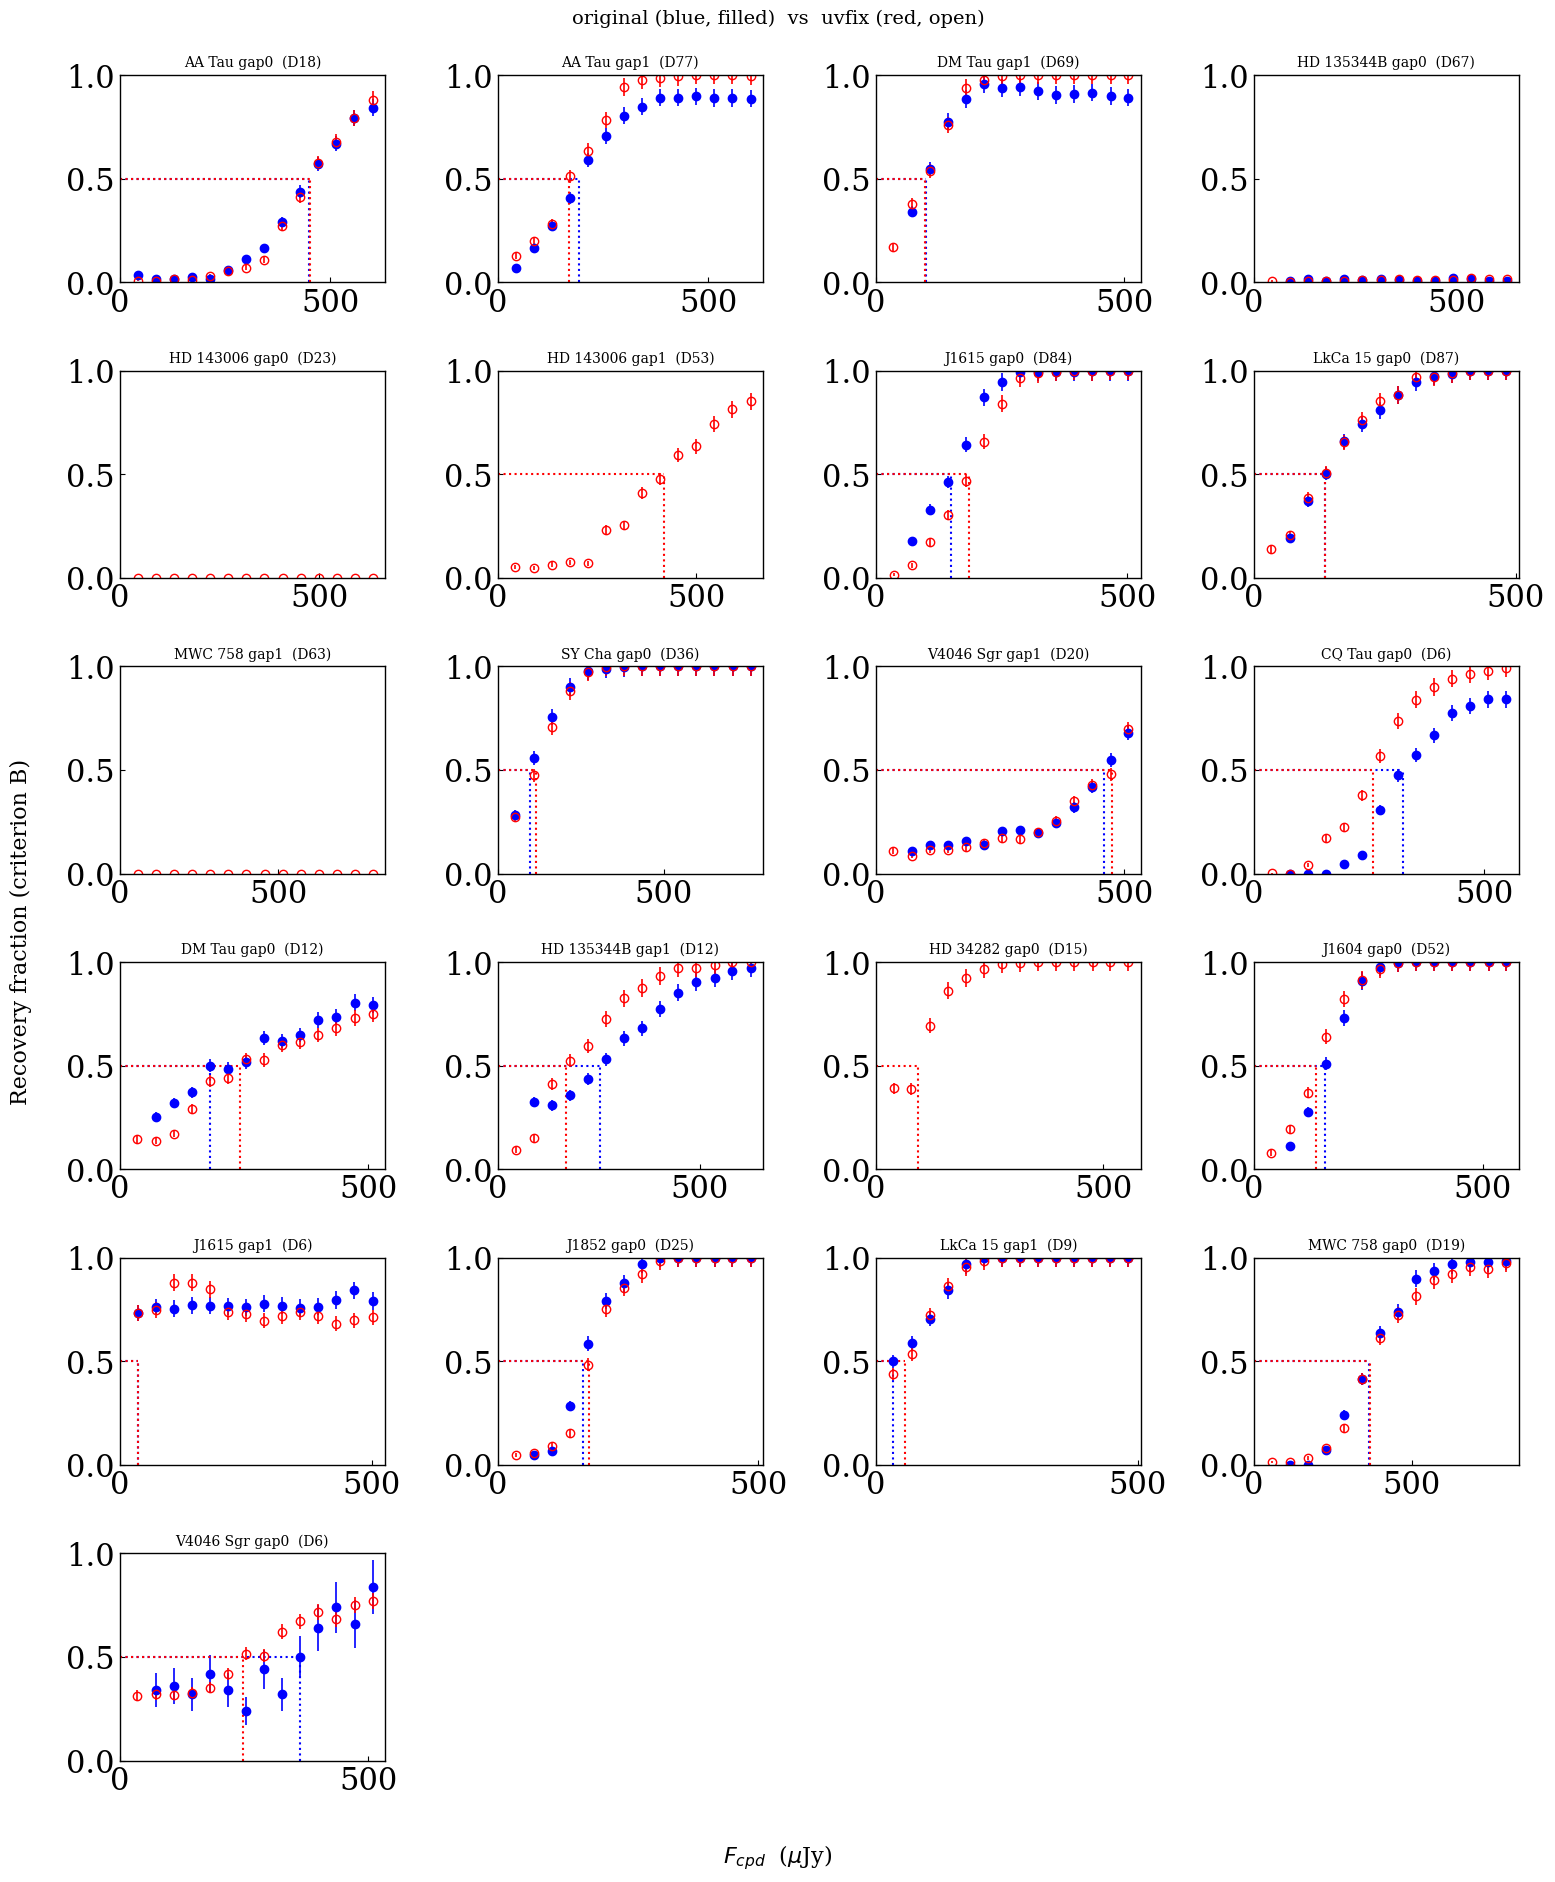

In [119]:
# recovery curves, original (blue, filled) vs uvfix (red, open), criterion B, dotted lines to each F50
names = [n for n, _, _, _ in TARGETS if old[n] is not None or new[n] is not None]
ncols = 4
fig, axes = plt.subplots(int(np.ceil(len(names) / ncols)), ncols, figsize=(4 * ncols, 3.2 * np.ceil(len(names) / ncols)))
for ax, name in zip(axes.flat, names):
    target, gap_ix = split(name)
    D_au = diskdict.disk[target]["rgap"][gap_ix] * diskdict.disk[target]["distance"]
    for d, c, mfc in [(old[name], "b", "b"), (new[name], "r", "none")]:
        if d is None:
            continue
        ax.errorbar(d[:, 0], d[:, 4], yerr=d[:, 5], marker="o", color=c, mfc=mfc, ls="none", capsize=0, elinewidth=1.2)
        F = f50(d[:, 0], d[:, 4])
        ax.hlines(0.5, 0, F, color=c, ls=":", lw=1.5)
        ax.vlines(F, 0, 0.5, color=c, ls=":", lw=1.5)
    ax.set_title(f"{name.replace('_', ' ')}  (D{D_au:.0f})", fontsize=10)
    ax.set_ylim(0, 1)
    ax.set_xlim(0, None)
for ax in axes.flat[len(names):]:
    ax.axis("off")
fig.supxlabel(r"$F_{cpd}$  ($\mu$Jy)", fontsize=16)
fig.supylabel("Recovery fraction (criterion B)", fontsize=16)
fig.suptitle("original (blue, filled)  vs  uvfix (red, open)", fontsize=14)
fig.tight_layout()
plt.show()

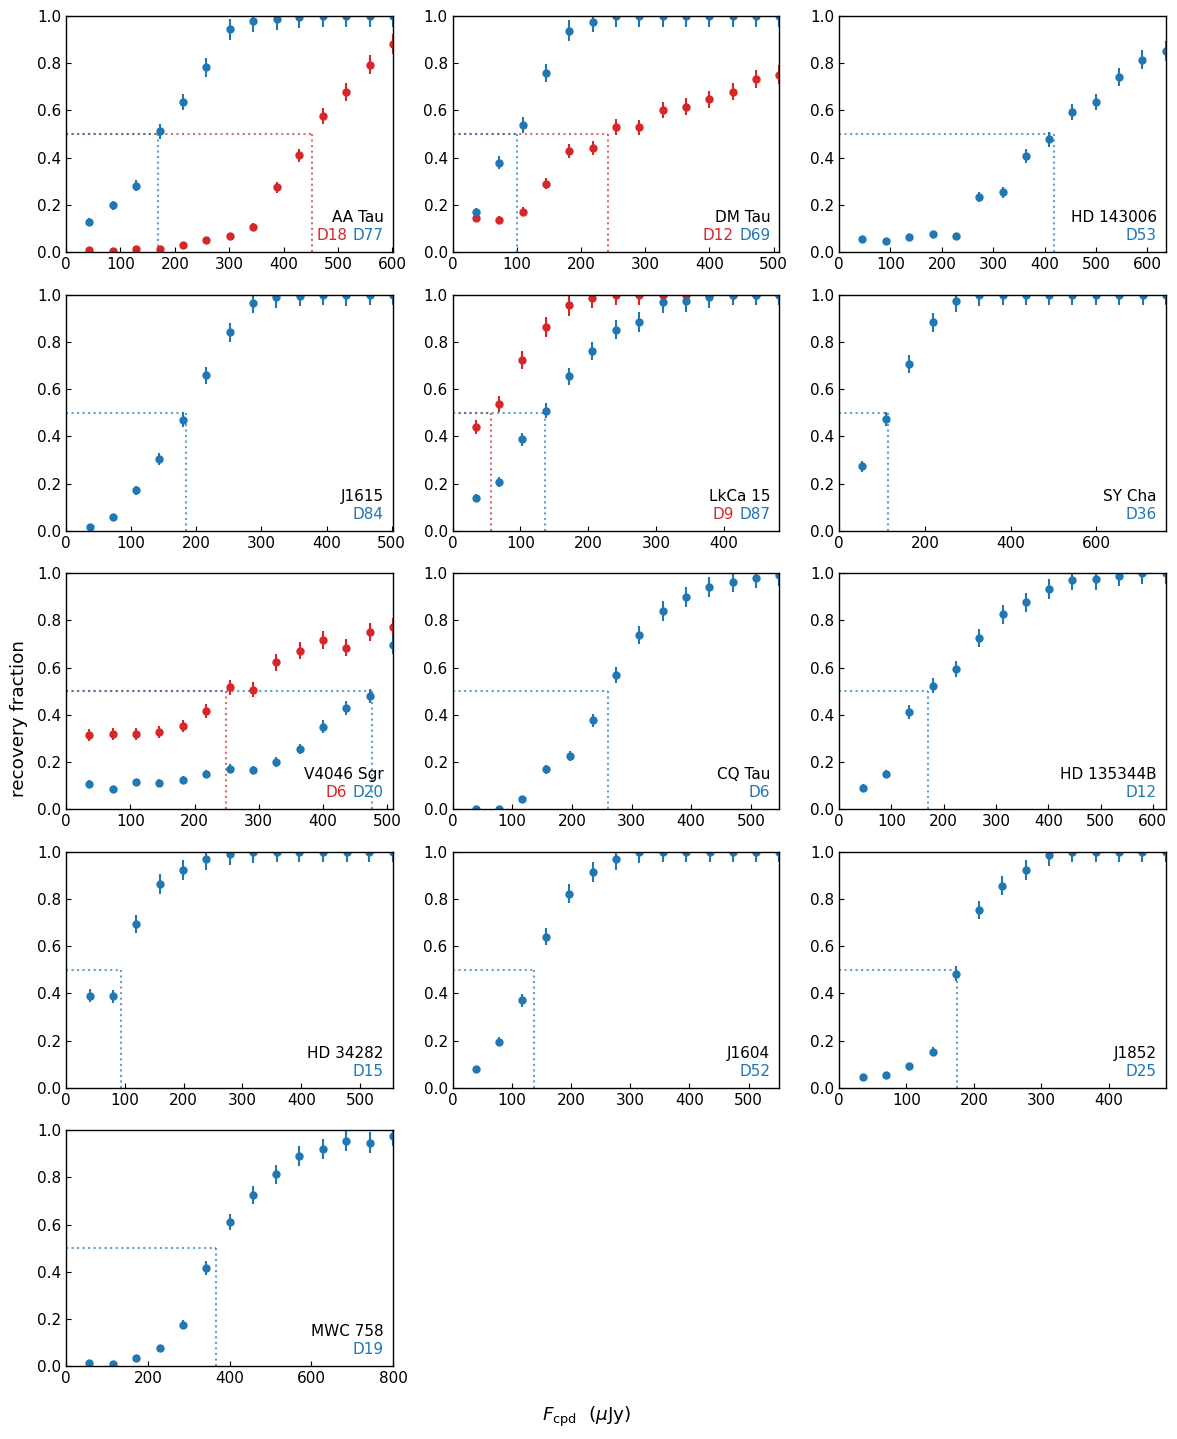

In [120]:
# updated summary grid (uvfix only), in the style of the DSHARP CPD-limit figure (Andrews et al. 2021): one panel
# per disk, criterion B; one gap -> blue, two gaps -> inner red / outer blue; dotted lines from the axes to each F50
from matplotlib.offsetbox import AnchoredOffsetbox, TextArea, HPacker, VPacker

# left out of this figure (no usable recovery curve): HD 135344B D67, HD 143006 D23 and MWC 758 D63 sit at ~0%
# (a fixed bright residual in the search annulus wins every time); J1615 D6 is flat (bright central residual)
SUMMARY_SKIP = {"HD_135344B_gap0", "HD_143006_gap0", "MWC_758_gap1", "J1615_gap1"}
disks = {}
for name, _, _, _ in TARGETS:
    if new[name] is not None and name not in SUMMARY_SKIP:
        disks.setdefault(split(name)[0], []).append(name)

def D_au(name):
    target, gap_ix = split(name)
    return diskdict.disk[target]["rgap"][gap_ix] * diskdict.disk[target]["distance"]

if not disks:
    print("No uvfix rprofs pulled back yet -- run make_rprofs_uvfix.py on the cluster and rsync the results first.")
else:
    ncols = 3
    nrows = int(np.ceil(len(disks) / ncols))
    with plt.rc_context({"font.family": "sans-serif", "font.size": 11, "axes.linewidth": 1.0}):
        fig, axes = plt.subplots(nrows, ncols, figsize=(12, 2.9 * nrows))
        for ax, (target, names) in zip(axes.flat, disks.items()):
            names = sorted(names, key=D_au)
            colors = ["tab:red", "tab:blue"] if len(names) == 2 else ["tab:blue"]
            for name, c in zip(names, colors):
                d = new[name]
                ax.errorbar(d[:, 0], d[:, 4], yerr=d[:, 5], fmt="o", color=c, ms=5, elinewidth=1.5, capsize=0)
                F = f50(d[:, 0], d[:, 4])
                ax.plot([0, F], [0.5, 0.5], ":", color=c, lw=1.5, alpha=0.7)
                ax.plot([F, F], [0, 0.5], ":", color=c, lw=1.5, alpha=0.7)
            # disk name, and below it the gap radii in the colour of their curves (inner first)
            d_row = HPacker(children=[TextArea(f"D{D_au(n):.0f}", textprops=dict(color=c)) for n, c in zip(names, colors)],
                            sep=4, align="baseline")
            label = VPacker(children=[TextArea(target.replace("_", " ")), d_row], sep=2, align="right")
            ax.add_artist(AnchoredOffsetbox(loc="lower right", child=label, frameon=False, pad=0.2, borderpad=0.4))
            ax.set_xlim(0, max(new[n][:, 0].max() for n in names))
            ax.set_ylim(0, 1)
        for ax in axes.flat[len(disks):]:
            ax.axis("off")
        fig.supxlabel(r"$F_{\rm cpd}$  ($\mu$Jy)")
        fig.supylabel("recovery fraction")
        fig.tight_layout()
        fig.savefig(r"E:\CPD_MPIA\CPD_Emission_Models\injrev_summary_uvfix.png", dpi=150, bbox_inches="tight")
        plt.show()

C1  F50_B =  439.5 uJy
C2  F50_B =    nan uJy
DF  F50_B =   89.0 uJy   (>= 50% at the lowest flux: upper limit)


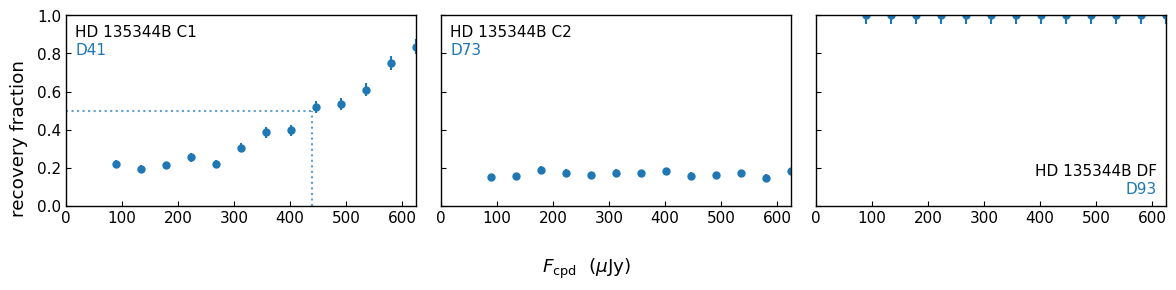

In [121]:
# HD_135344B point candidates: uvfix runs, criterion B, in the same style as the summary grid. Dotted lines to each
# F50, left out where recovery is already >= 50% at the lowest flux (F50 is then only an upper limit: DF).
# D = candidate radius in au (as in the emission cell).
from matplotlib.offsetbox import AnchoredOffsetbox, TextArea, VPacker

with plt.rc_context({"font.family": "sans-serif", "font.size": 11, "axes.linewidth": 1.0}):
    fig, axes = plt.subplots(1, 3, figsize=(12, 2.9), sharey=True)
    for ax, (cand, g, D) in zip(axes, [("C1", 2, 41), ("C2", 3, 73), ("DF", 4, 93)]):
        d = rprofs(rf"gap\HD_135344B_{cand}_uvfix", f"HD_135344B_gap{g}")
        ax.errorbar(d[:, 0], d[:, 4], yerr=d[:, 5], fmt="o", color="tab:blue", ms=5, elinewidth=1.5, capsize=0)
        F = f50(d[:, 0], d[:, 4])
        if d[0, 4] < 0.5:
            ax.plot([0, F], [0.5, 0.5], ":", color="tab:blue", lw=1.5, alpha=0.7)
            ax.plot([F, F], [0, 0.5], ":", color="tab:blue", lw=1.5, alpha=0.7)
        print(f"{cand}  F50_B = {F:6.1f} uJy" + ("   (>= 50% at the lowest flux: upper limit)" if d[0, 4] >= 0.5 else ""))
        # label where the panel is empty: top left if the curve is mostly low, else bottom right
        loc = "upper left" if d[:, 4].mean() < 0.5 else "lower right"
        label = VPacker(children=[TextArea(f"HD 135344B {cand}"), TextArea(f"D{D}", textprops=dict(color="tab:blue"))],
                        sep=2, align="left" if loc == "upper left" else "right")
        ax.add_artist(AnchoredOffsetbox(loc=loc, child=label, frameon=False, pad=0.2, borderpad=0.4))
        ax.set_xlim(0, d[:, 0].max())
        ax.set_ylim(0, 1)
    fig.supxlabel(r"$F_{\rm cpd}$  ($\mu$Jy)")
    fig.supylabel("recovery fraction")
    fig.tight_layout()
    plt.show()

HD_143006: no pipeline residual image -- beam from the archival exoALMA residual
HD_34282: no pipeline residual image -- beam from the archival exoALMA residual


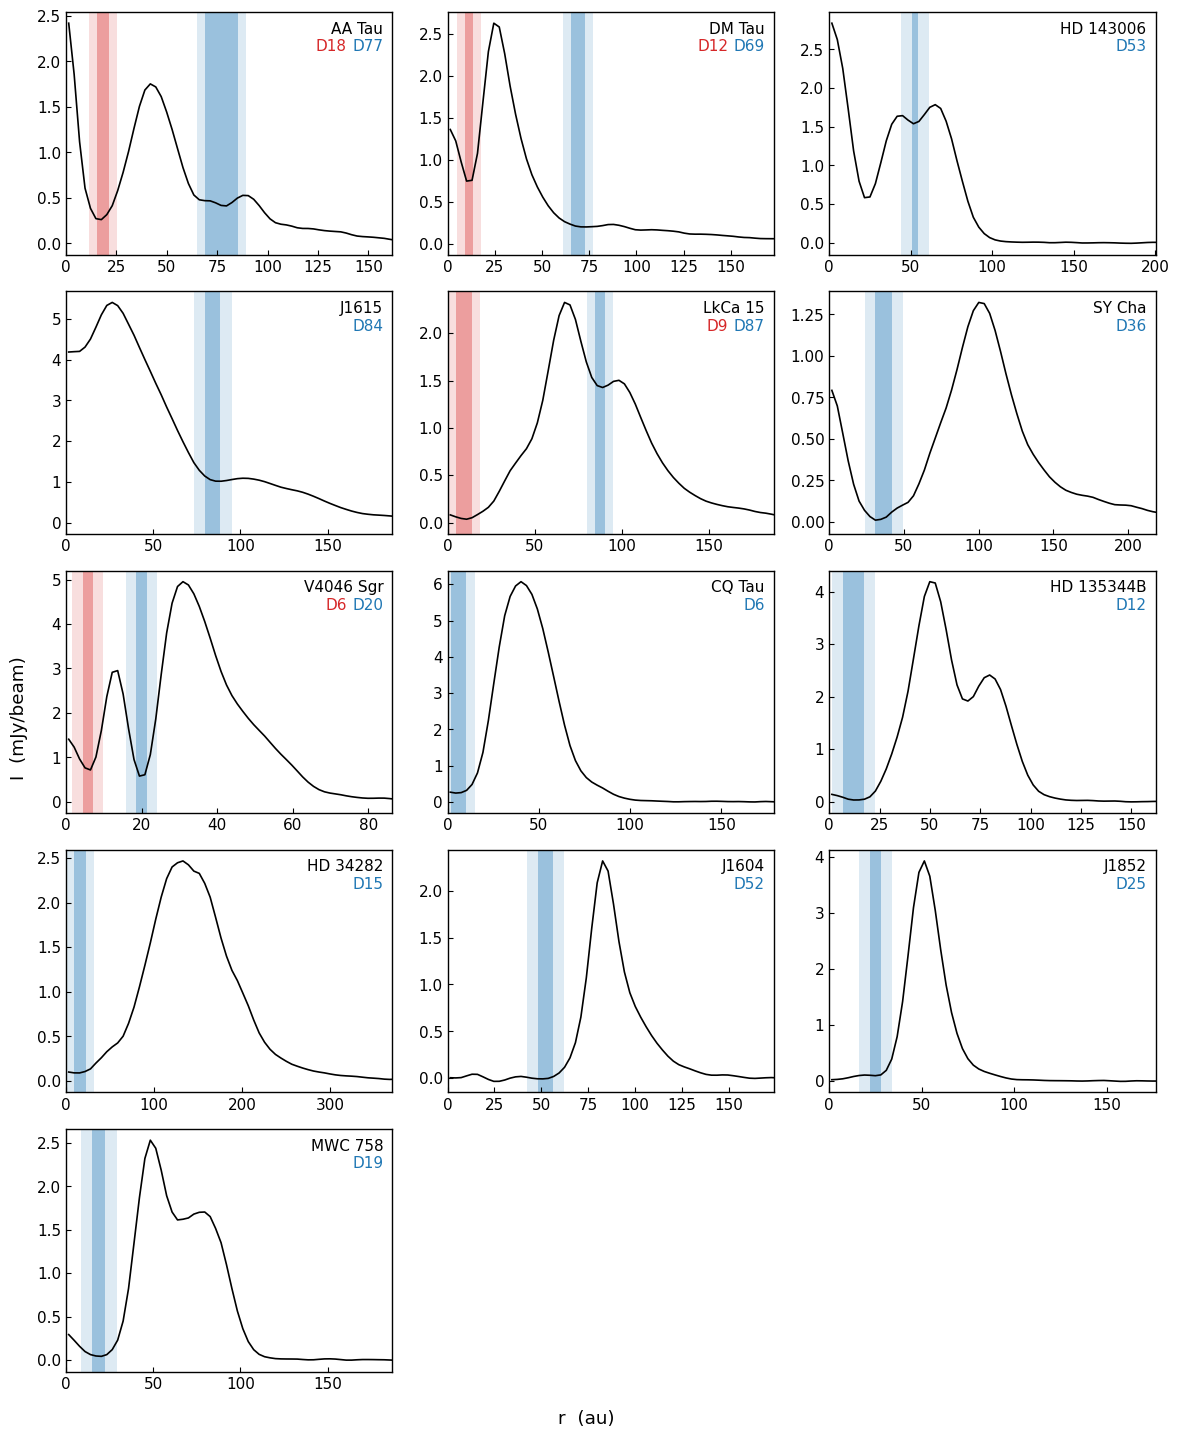

In [122]:
# radial profiles (CLEAN, robust=-0.5) for the gaps shown in the summary grid above -- same panels, order, colours and
# label style (uses `disks` and D_au from that cell). Dark band: injection zone rgap +/- 0.5*wgap; light band: search
# annulus rgap +/- (0.5*wgap + 0.5*beam). One gap -> blue, two gaps -> inner red / outer blue.
import glob
from astropy.io import fits
from matplotlib.offsetbox import AnchoredOffsetbox, TextArea, HPacker, VPacker

folders = {n: (o, u) for n, _, o, u in TARGETS}
ncols = 3
nrows = int(np.ceil(len(disks) / ncols))
with plt.rc_context({"font.family": "sans-serif", "font.size": 11, "axes.linewidth": 1.0}):
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 2.9 * nrows))
    for ax, (target, names) in zip(axes.flat, disks.items()):
        distance = diskdict.disk[target]["distance"]
        prof = np.loadtxt(rf"E:\exoALMA_disk_data\{target}\{target}_CLEAN_profile_robust-05.txt", comments="#")
        ax.plot(prof[:, 0] * distance, prof[:, 2], "k-", lw=1.2)

        # pipeline beam from a residual image of this disk (uvfix run first, else the original run);
        # the archival exoALMA residual's beam is ~6% larger, so it is only the last resort
        fits_files = [f for n in names for d in (folders[n][1], folders[n][0]) if d
                      for f in sorted(glob.glob(rf"{base}\{d}\recoveries\*.resid.fits"))]
        if not fits_files:
            fits_files = glob.glob(rf"E:\exoALMA_disk_data\{target}\images_frank_residuals_different_robust\*robust-0.5.image.fits")
            print(f"{target}: no pipeline residual image -- beam from the archival exoALMA residual")
        hd = fits.getheader(fits_files[0])
        beam_fwhm = np.sqrt(3600**2 * hd["BMAJ"] * hd["BMIN"])

        names = sorted(names, key=D_au)
        colors = ["tab:red", "tab:blue"] if len(names) == 2 else ["tab:blue"]
        for name, c in zip(names, colors):
            gap_ix = split(name)[1]
            rgap, wgap = diskdict.disk[target]["rgap"][gap_ix], diskdict.disk[target]["wgap"][gap_ix]
            search = 0.5 * wgap + 0.5 * beam_fwhm
            ax.axvspan((rgap - search) * distance, (rgap + search) * distance, color=c, alpha=0.15, lw=0)
            ax.axvspan((rgap - 0.5 * wgap) * distance, (rgap + 0.5 * wgap) * distance, color=c, alpha=0.35, lw=0)

        d_row = HPacker(children=[TextArea(f"D{D_au(n):.0f}", textprops=dict(color=c)) for n, c in zip(names, colors)],
                        sep=4, align="baseline")
        label = VPacker(children=[TextArea(target.replace("_", " ")), d_row], sep=2, align="right")
        ax.add_artist(AnchoredOffsetbox(loc="upper right", child=label, frameon=False, pad=0.2, borderpad=0.4))
        ax.set_xlim(0, 1.2 * distance)
    for ax in axes.flat[len(disks):]:
        ax.axis("off")
    fig.supxlabel("r  (au)")
    fig.supylabel("I  (mJy/beam)")
    fig.tight_layout()
    plt.show()

AA_Tau   N/bin =  500  D = 80 au  F50_B = 43.0 uJy   (>= 50% at the lowest flux: upper limit)
SY_Cha   N/bin =  500  D = 140 au  F50_B = 150.4 uJy
J1615    N/bin =  500  D = 310 au  F50_B = 84.5 uJy
LkCa_15  N/bin =  500  D = 240 au  F50_B = 94.8 uJy
J1842    N/bin =  500  D = 105 au  F50_B = 137.5 uJy


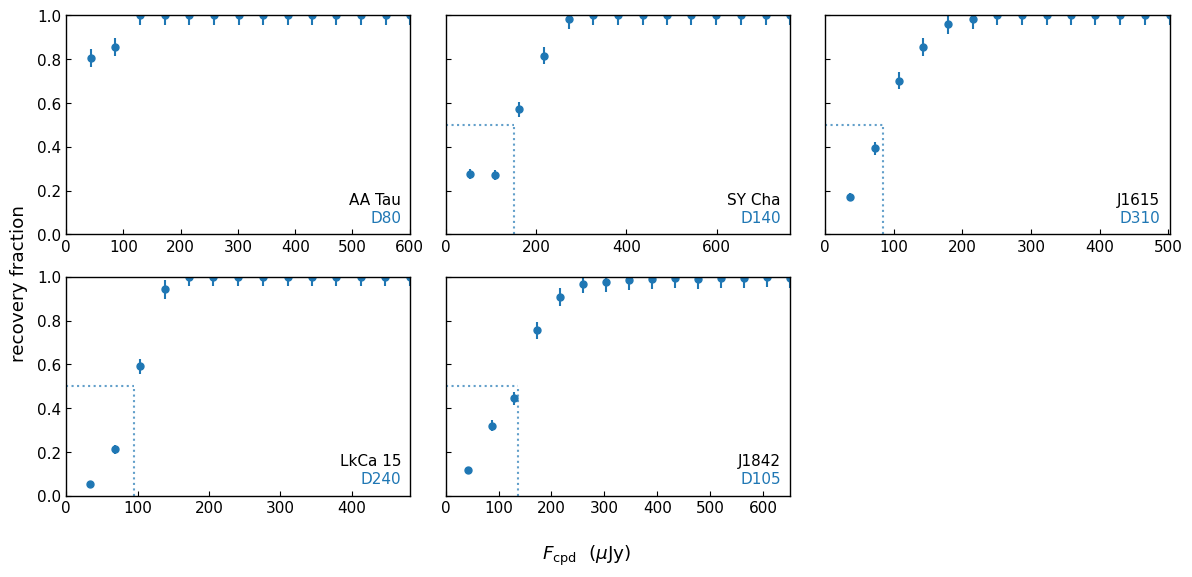

In [123]:
# kink candidates: recovery fraction (criterion B) of the uv-fixed runs -- as HPC_kink_spartan/assess_kink0.ipynb cell 13,
# drawn in the summary-grid style. No F50 lines where recovery is already >= 50% at the lowest flux (AA Tau: upper limit).
# The runs (uvfix folder + kink0_rep1-9) are already combined in {target}_kink0_uvfix/recoveries/*_recoveries.combined.txt.
# Criterion B needs the longest baseline, Bmax = wave(CRVAL3) * max|uv| of the single-wavelength npz; the npz is only
# on the cluster, so max|uv| per disk is read from uvmax_lambda.txt (made once on Node-01, see the top of the notebook).
import glob
from astropy.io import fits
from matplotlib.offsetbox import AnchoredOffsetbox, TextArea, VPacker

kink_base = r"E:\CPD_MPIA\HPC_kink_spartan"
uvmax_file = r"E:\CPD_MPIA\HPC_eqC1_gap\uvmax_lambda.txt"
Kink = [("AA_Tau", 2), ("SY_Cha", 1), ("J1615", 2), ("LkCa_15", 2), ("J1842", 0)]   # target, gap label in the file names
npix_tol, ast_tol = 2, 2

if not os.path.exists(uvmax_file):
    print("uvmax_lambda.txt not found -- see the top of the notebook.")
else:
    uvmax = {l.split()[0]: float(l.split()[1]) for l in open(uvmax_file)}
    with plt.rc_context({"font.family": "sans-serif", "font.size": 11, "axes.linewidth": 1.0}):
        fig, axes = plt.subplots(2, 3, figsize=(12, 2 * 2.9), sharey=True)
        for ax, (target, gap) in zip(axes.flat, Kink):
            folder = rf"{kink_base}\{target}_kink0_uvfix"
            Fi, Fr, mdl, ri, rr, azi, azr, xr, yr, mu, rms = np.loadtxt(rf"{folder}\recoveries\{target}_gap{gap}_recoveries.combined.txt").T
            inclr, PAr = np.radians(diskdict.disk[target]["incl"]), np.radians(diskdict.disk[target]["PA"])
            azir = np.radians(azi)
            xi = ri * np.sin(azir) * np.sin(PAr) + ri * np.cos(azir) * np.cos(inclr) * np.cos(PAr)
            yi = ri * np.sin(azir) * np.cos(PAr) - ri * np.cos(azir) * np.cos(inclr) * np.sin(PAr)
            d_ir = np.hypot(xi - xr, yi - yr)
            hd = fits.getheader(sorted(glob.glob(rf"{folder}\recoveries\*.resid.fits"))[0])
            pix_size = np.abs(3600 * hd["CDELT2"])
            freq, wave = hd["CRVAL3"], 2.99792e5 / hd["CRVAL3"]   # Hz, km
            sigma_B = 70 / ((freq / 1e9) * (wave * uvmax[target]) * Fr / rms)
            rec = d_ir <= np.maximum(ast_tol * sigma_B, npix_tol * pix_size)

            Fcpd = np.unique(Fi)
            N = np.array([np.sum(Fi == F) for F in Fcpd])
            n = np.array([np.sum(rec[Fi == F]) for F in Fcpd])
            frec_B, efrec_B = n / N, np.sqrt(n) / N
            F = f50(Fcpd, frec_B)
            D_kink = diskdict.disk[target]["rkink"][0] * diskdict.disk[target]["distance"]

            ax.errorbar(Fcpd, frec_B, yerr=efrec_B, fmt="o", color="tab:blue", ms=5, elinewidth=1.5, capsize=0)
            if frec_B[0] < 0.5:
                ax.plot([0, F], [0.5, 0.5], ":", color="tab:blue", lw=1.5, alpha=0.7)
                ax.plot([F, F], [0, 0.5], ":", color="tab:blue", lw=1.5, alpha=0.7)
            label = VPacker(children=[TextArea(target.replace("_", " ")), TextArea(f"D{D_kink:.0f}", textprops=dict(color="tab:blue"))],
                            sep=2, align="right")
            ax.add_artist(AnchoredOffsetbox(loc="lower right", child=label, frameon=False, pad=0.2, borderpad=0.4))
            ax.set_xlim(0, Fcpd.max())
            ax.set_ylim(0, 1)
            print(f"{target:8s} N/bin = {N[0]:4d}  D = {D_kink:.0f} au  F50_B = {F:.1f} uJy"
                  + ("   (>= 50% at the lowest flux: upper limit)" if frec_B[0] >= 0.5 else ""))
        for ax in axes.flat[len(Kink):]:
            ax.axis("off")
        fig.supxlabel(r"$F_{\rm cpd}$  ($\mu$Jy)")
        fig.supylabel("recovery fraction")
        fig.tight_layout()
        plt.show()

In [124]:
# updated F50 lists for kink_emission_models.ipynb (cells 3, 5 and 6) -- paste over the old ones
# Format there: [disk_name, radius_au, F50_ujy]; gap_ix dicts are keyed by (disk_name, radius_au)
good = table[table["F50_uvfix_uJy"].notna() & ~table["name"].isin(list(EXCLUDE))]
for cat, var, ixvar in [("gap", "gap_sources", "gap_ix_by_source"), ("cavity", "inner_cavity_sources", "cavity_gap_ix")]:
    sub = good[good["category"] == cat]
    print(f"{var} = [")
    for _, r in sub.iterrows():
        print(f'    ["{split(r["name"])[0]}", {r["D_au"]:>3d}, {r["F50_uvfix_uJy"]:.1f}],')
    print("]")
    print(f"{ixvar} = {{" + ", ".join(f'("{split(n)[0]}", {d}): {split(n)[1]}' for n, d in zip(sub["name"], sub["D_au"])) + "}\n")

print("curated_gap_sources = gap_sources + inner_cavity_sources   # or keep the per-target ordering of cell 6")
print("\nnot in the lists:", {n: EXCLUDE[n] for n in EXCLUDE},
      "| no uvfix result yet:", list(table.loc[table['F50_uvfix_uJy'].isna() & ~table['name'].isin(list(EXCLUDE)), 'name']))

gap_sources = [
    ["AA_Tau",  18, 452.0],
    ["AA_Tau",  77, 169.8],
    ["DM_Tau",  69, 100.4],
    ["HD_143006",  53, 417.7],
    ["J1615",  84, 184.7],
    ["LkCa_15",  87, 135.7],
    ["SY_Cha",  36, 115.1],
    ["V4046_Sgr",  20, 476.3],
]
gap_ix_by_source = {("AA_Tau", 18): 0, ("AA_Tau", 77): 1, ("DM_Tau", 69): 1, ("HD_143006", 53): 1, ("J1615", 84): 0, ("LkCa_15", 87): 0, ("SY_Cha", 36): 0, ("V4046_Sgr", 20): 1}

inner_cavity_sources = [
    ["CQ_Tau",   6, 259.8],
    ["DM_Tau",  12, 242.4],
    ["HD_135344B",  12, 169.4],
    ["HD_34282",  15, 93.6],
    ["J1604",  52, 137.3],
    ["J1852",  25, 175.1],
    ["LkCa_15",   9, 56.1],
    ["MWC_758",  19, 367.4],
    ["V4046_Sgr",   6, 249.1],
]
cavity_gap_ix = {("CQ_Tau", 6): 0, ("DM_Tau", 12): 0, ("HD_135344B", 12): 1, ("HD_34282", 15): 0, ("J1604", 52): 0, ("J1852", 25): 0, ("LkCa_15", 9): 1, ("MWC_758", 19): 0, ("V4046_Sgr", 6): 0}

curated_gap_sources = gap_sources + inner_cavity_sources   # or keep the per-target ordering

In [125]:
# emission-model functions -- copied from kink_emission_models.ipynb cell 0; one change: get_andrews_grid adds
# the F50 to the cache name for mode "uvfix" (see there)
# (Andrews / Zhu grids cached in Andrews_npz/, and plot_emission_grid). Sets serif/22pt fonts for the plots below.
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib as mpl

sys.path.append(r"E:\CPD_MPIA\CPD_Emission_Models")
os.chdir(r"E:\CPD_MPIA\CPD_Emission_Models")   # caches live relative to cwd
import Zhu_model, Andrew_model
from Dictionaries import disk_arr

rcParams["font.size"] = 22
rcParams["font.family"] = "serif"
rcParams["axes.linewidth"] = 1.0
rcParams["xtick.direction"] = "in"
rcParams["ytick.direction"] = "in"

def _clim(m):
    if m is None:
        return None
    if hasattr(m, "get_clim"):
        return m.get_clim()
    if hasattr(m, "collections") and m.collections:
        return m.collections[0].get_clim()
    return None

def _apply_norm(m, norm):
    if m is None:
        return
    if hasattr(m, "set_norm"):
        m.set_norm(norm)
        return
    if hasattr(m, "collections") and m.collections:
        for c in m.collections:
            c.set_norm(norm)

def add_row_colorbar(fig, axes_row, mapps, label, pad=0.02, fraction=0.046, vmin=None, vmax=None):
    mapps = [m for m in mapps if m is not None]
    clims = [c for c in (_clim(m) for m in mapps) if c is not None]
    if not clims:
        return None
    if vmin is None:
        vmin = min(c[0] for c in clims)
    if vmax is None:
        vmax = max(c[1] for c in clims)
    norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
    for m in mapps:
        _apply_norm(m, norm)
    cmap = getattr(mapps[0], "cmap", mpl.cm.viridis)
    sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cb = fig.colorbar(sm, ax=list(axes_row), fraction=fraction, pad=pad)
    cb.set_label(label, fontsize=rcParams["font.size"])
    cb.ax.tick_params(labelsize=rcParams["font.size"] * 0.9)
    return cb

# n_jobs for the Andrews grid computation -- kept low (2) since running many
# disks back-to-back at n_jobs=4+ pegs a laptop's CPU for the whole notebook run
ANDREWS_N_JOBS = 2
ANDREWS_NPZ_DIR = "Andrews_npz"

def get_andrews_grid(disk_name, disk_radius, sigma_ujy, mode, alpha=1e-3, mcpd_max=-3):
    """Andrews (Mp, Rout/R_Hill) grid, cached to .npz -- so re-running this cell
    later just to tweak plot style (colors, ranges, labels) never recomputes."""
    os.makedirs(ANDREWS_NPZ_DIR, exist_ok=True)
    # mcpd_max: top of the CPD-mass search grid (log10 M_Jup); cells needing more mass stay white.
    # Only a non-default value goes into the file name, so the existing caches stay valid.
    tag = "" if mcpd_max == -3 else f"_mcpdmax{mcpd_max}"
    # "_mdotMp": grids made with Mdot = Mp / 1 Myr (Andrew_model.compute_flux_map); older caches without it used a
    # fixed Mdot = 1.56 Mjup/Myr and are left in place, never loaded here
    tag += "_mdotMp"
    # uvfix_update.ipynb only: for mode "uvfix" the file name also carries this source's F50, since the grid
    # depends on it -- a changed F50 is recomputed, an unchanged one is loaded whatever batch it is plotted in
    if mode == "uvfix":
        tag += f"_F{sigma_ujy:.1f}"
    npz_path = f"{ANDREWS_NPZ_DIR}/{disk_name}_{disk_radius}_alpha{alpha}_{mode}{tag}.npz"
    if os.path.exists(npz_path):
        d = np.load(npz_path)
        return d["Mp_grid"], d["Rout_frac_grid"], d["Flux_vals"], d["M_cpd_chosen"]

    Mp_grid, Rout_frac_grid, Flux_vals, M_cpd_chosen = Andrew_model.compute_flux_map(
        target_flux_arr=[sigma_ujy], disk_arr=disk_arr[disk_name],
        rp=disk_radius, alpha=alpha, mode=mode, verbose=False, mcpd_max=mcpd_max,
        save=False, n_jobs=ANDREWS_N_JOBS,
    )
    np.savez(npz_path, Mp_grid=Mp_grid, Rout_frac_grid=Rout_frac_grid,
             Flux_vals=Flux_vals, M_cpd_chosen=M_cpd_chosen)
    return Mp_grid, Rout_frac_grid, Flux_vals, M_cpd_chosen

def get_zhu_mpmdot_grid(disk_name, disk_radius, mode, alpha=1e-3,
                         mp_min=-2, mp_max=1, n_mp=100,
                         mdot_min=-8, mdot_max=-5, n_mdot=100):
    """Zhu (Mp, Mdot) flux grid, cached to .npz -- same convention as get_andrews_grid.
    Also returns Tau_vals2 (tau_mm at the disk's inner edge -- Zhu_model's own
    Tb_from_tau uses exactly this tau_mm to switch between the optically-thick
    branch, Tb=((3/8)(kappaR/kappa_mm)Teff^4+Text^4)^0.25 -- no Sigma dependence,
    heating-dominated -- and the thin branch, Tb=2*tau*Tc -- linear in Sigma via
    tau=0.5*kappa_mm*Sigma. So tau=0.5 IS the model's real thick/thin switch,
    not an external threshold -- kept available here even though it's not
    currently plotted, pulled from the same calculate_disk_properties_zhu call
    already made for Flux_vals2 so there's no extra cost to keeping it)."""
    os.makedirs(ANDREWS_NPZ_DIR, exist_ok=True)
    npz_path = (f"{ANDREWS_NPZ_DIR}/{disk_name}_{disk_radius}_zhu_mpmdot_{mode}"
                f"_a{alpha}_mp{mp_min}_{mp_max}_{n_mp}_md{mdot_min}_{mdot_max}_{n_mdot}.npz")
    if os.path.exists(npz_path):
        d = np.load(npz_path)
        if "Tau_vals2" in d.files:
            return d["Mp_grid2"], d["Mdot_grid"], d["Flux_vals2"], d["Tau_vals2"]

    Mp_grid2 = np.logspace(mp_min, mp_max, n_mp)
    Mdot_grid = np.logspace(mdot_min, mdot_max, n_mdot)
    Flux_vals2 = np.zeros((len(Mdot_grid), len(Mp_grid2)))
    Tau_vals2 = np.zeros((len(Mdot_grid), len(Mp_grid2)))
    for i, Mdot in enumerate(Mdot_grid):
        for j, Mp in enumerate(Mp_grid2):
            RHill = disk_radius * (Mp / (3 * 1047.56 * disk_arr[disk_name][1])) ** (1 / 3)
            out = Zhu_model.calculate_disk_properties_zhu(
                M_star=disk_arr[disk_name][1], Mp=Mp, Mdot=Mdot, alpha=alpha,
                rp=disk_radius, d_pc=disk_arr[disk_name][2], lam_mm=0.9,
                Rout=0.3 * RHill, Lstar=disk_arr[disk_name][3],
            )
            Flux_vals2[i, j] = out["F_nu_tot"]
            Tau_vals2[i, j] = out["tau_mm"][0]
    np.savez(npz_path, Mp_grid2=Mp_grid2, Mdot_grid=Mdot_grid, Flux_vals2=Flux_vals2, Tau_vals2=Tau_vals2)
    return Mp_grid2, Mdot_grid, Flux_vals2, Tau_vals2

def get_zhu_mpalpha_grid(disk_name, disk_radius, mode,
                          mp_min=-2, mp_max=1, n_mp=80,
                          alpha_min=-4, alpha_max=-1, n_alpha=80,
                          Mdot=None):
    """Zhu (Mp, alpha) flux grid, cached to .npz -- same convention as get_andrews_grid.
    Mdot=None (default): Zhu_model uses its Mdot=Mp/1e6 scaling. Pass a fixed
    value (Mjup/yr) to hold Mdot constant across the grid instead.
    Also returns Tau_map (tau_mm at the disk's inner edge, see get_zhu_mpmdot_grid's
    docstring -- kept available, not currently plotted) -- looped directly
    (rather than via Zhu_model.compute_flux_map_zhu_MpAlpha) so we can pull
    tau_mm out of the same calculate_disk_properties_zhu call without touching
    that shared function's return signature, which other notebooks rely on."""
    os.makedirs(ANDREWS_NPZ_DIR, exist_ok=True)
    npz_path = (f"{ANDREWS_NPZ_DIR}/{disk_name}_{disk_radius}_zhu_mpalpha_{mode}"
                f"_mp{mp_min}_{mp_max}_{n_mp}_al{alpha_min}_{alpha_max}_{n_alpha}_md{Mdot}.npz")
    if os.path.exists(npz_path):
        d = np.load(npz_path)
        if "Tau_map" in d.files:
            return d["Mp_grid_alpha"], d["alpha_grid"], d["Flux_map"], d["Tau_map"]

    Mp_grid_alpha = np.logspace(mp_min, mp_max, n_mp)
    alpha_grid = np.logspace(alpha_min, alpha_max, n_alpha)
    Flux_map = np.zeros((n_alpha, n_mp))
    Tau_map = np.zeros((n_alpha, n_mp))
    M_star_jup = disk_arr[disk_name][1] * 1047.56
    for j, Mp in enumerate(Mp_grid_alpha):
        RHill = disk_radius * (Mp / (3 * M_star_jup)) ** (1 / 3)
        Rout = 0.3 * RHill
        for i, alpha_val in enumerate(alpha_grid):
            Mdot_use = (Mp / 1e6) if (Mdot is None) else Mdot
            out = Zhu_model.calculate_disk_properties_zhu(
                M_star=disk_arr[disk_name][1], Mp=Mp, Mdot=Mdot_use, alpha=alpha_val,
                rp=disk_radius, d_pc=disk_arr[disk_name][2], lam_mm=0.9,
                Rout=Rout, Lstar=disk_arr[disk_name][3],
            )
            Flux_map[i, j] = out["F_nu_tot"]
            Tau_map[i, j] = out["tau_mm"][0]
    np.savez(npz_path, Mp_grid_alpha=Mp_grid_alpha, alpha_grid=alpha_grid, Flux_map=Flux_map, Tau_map=Tau_map)
    return Mp_grid_alpha, alpha_grid, Flux_map, Tau_map

def heating_vs_sigma_slope(alpha_grid, Flux_map):
    """d(ln F)/d(ln alpha) at fixed Mdot, from row 3's own flux grid -- a
    complementary check to tau=0.5: alpha's only job in the Zhu model is
    setting Sigma, never the heating rate, so slope~0 confirms heating-
    dominated (tau>0.5 branch) and slope~-1 confirms Sigma-dominated (tau<0.5
    branch). Used by the summary-table cells below."""
    return np.gradient(np.log(Flux_map), np.log(alpha_grid), axis=0)

def plot_emission_grid(
    sources, mode, planet_masses=None,
    # Row 1 -- Andrews: Mp vs Rout/R_Hill
    andrews_alpha=1e-3, andrews_x_min=-2, andrews_x_max=1,
    andrews_y_min=0.05, andrews_y_max=0.8,
    andrews_cmin=-5.5, andrews_cmax=-2.5,
    andrews_mcpd_max=-3,   # top of the CPD-mass search (log10 M_Jup), see get_andrews_grid
    # Row 2 -- Zhu: Mp vs Mdot
    zhu2_alpha=1e-3,
    zhu2_mp_min=-2, zhu2_mp_max=1, zhu2_n_mp=100,
    zhu2_mdot_min=-8, zhu2_mdot_max=-5, zhu2_n_mdot=100,
    # per-column viscosity override for row 2 -- {(disk_name, disk_radius): alpha},
    # falls back to zhu2_alpha where absent. Panel is annotated with the
    # overridden value so the change is visible on the plot.
    zhu2_alpha_by_col=None,
    # Row 3 -- Zhu: Mp vs alpha
    zhu3_mp_min=-2, zhu3_mp_max=1, zhu3_n_mp=80,
    zhu3_alpha_min=-4, zhu3_alpha_max=-1, zhu3_n_alpha=80,
    # per-column fixed-Mdot override for row 3 -- {(disk_name, disk_radius): Mdot_Mjup_per_yr},
    # replaces the default Mdot=Mp/1e6 scaling with a constant accretion rate
    # (e.g. the row-2 F50 intersection value). Panel is annotated when set.
    zhu3_mdot_by_col=None,
    # shared row colorbars -- row 1 defaults to andrews_cmin/andrews_cmax (same
    # values used for each panel's own contourf levels); rows 2/3 default to
    # None, which auto-scales from the plotted data as before
    zhu2_cbar_vmin=None, zhu2_cbar_vmax=None,
    zhu3_cbar_vmin=None, zhu3_cbar_vmax=None,
    # optional {(disk_name, disk_radius): gap_boundary_au} -- hatches the
    # region on row 1 where R_cpd > this boundary (e.g. 2*wgap for a real
    # gap; keyed by (disk_name, radius) since one disk can have >1 gap in
    # the same sources list. No natural analog for kinks -- omit the entry
    # to skip it there.
    gap_boundary_au=None,
    # optional {(disk_name, disk_radius): mass_Mjup} -- draws a magenta dashed
    # vertical line with a left-pointing arrow on every row, indicating an
    # upper limit (Mp < value) rather than a fixed estimate. Distinct from
    # planet_masses below since a single disk can have multiple columns here.
    mass_upper_limits=None,
    # set False to skip the faint dashed Mp=1 Mjup reference line -- redundant
    # once a magenta planet_masses/mass_upper_limits line is already drawn
    # (e.g. the kink candidate plots)
    show_mp1_line=True,
):
    """sources: list of (disk_name, radius_au, flux_ujy). mode: cache-file tag (e.g. 'gap', 'kink').
    planet_masses: optional {disk_name: mass_Mjup} or {(disk_name, disk_radius): mass_Mjup}
    -- draws a magenta vertical line at that mass on every row (all three rows
    share a log10(Mp) x-axis). The tuple-key form disambiguates multiple
    columns of the same disk_name; disk_name-only keys apply to every column
    of that disk (original behavior).
    mass_upper_limits: see above -- upper-limit arrow variant, tuple-keyed only.
    All defaults match the original hardcoded values -- pass any of the
    andrews_*/zhu2_*/zhu3_* kwargs to override without editing this function."""
    fig, axes = plt.subplots(3, len(sources), figsize=(6 * len(sources), 15), sharex=False, sharey=False, constrained_layout=True)
    if len(sources) == 1:
        axes = axes[:, None]
    row_mappables = [[], [], []]

    for col, (disk_name, disk_radius, sigma_ujy) in enumerate(sources):
        axes[0, col].set_title(
            f"{disk_name.replace('_',' ')} (r={disk_radius:.0f} au)",
            fontsize=rcParams["font.size"], pad=10, fontweight="bold",
        )

        # ROW 1 -- Andrews: Mp vs Rout/R_Hill, colored by log10(M_CPD)
        ax = axes[0, col]
        ax.set_aspect("auto")
        Mp_grid, Rout_frac_grid, Flux_vals, M_cpd_chosen = get_andrews_grid(
            disk_name, disk_radius, sigma_ujy, mode, alpha=andrews_alpha, mcpd_max=andrews_mcpd_max,
        )
        im = Andrew_model.plot_flux_map(
            Mp_grid, Rout_frac_grid, Flux_vals, M_cpd_chosen,
            disk_arr=disk_arr[disk_name], ax=ax,
            rp=disk_radius, alpha=andrews_alpha,
            x_min=andrews_x_min, x_max=andrews_x_max, y_min=andrews_y_min, y_max=andrews_y_max,
            min=andrews_cmin, max=andrews_cmax,
            res_au=disk_arr[disk_name][4] * disk_arr[disk_name][2],
            sigma_ujy=sigma_ujy, det_sigma=5,
            gap_boundary_au=(gap_boundary_au or {}).get((disk_name, disk_radius)),
        )
        row_mappables[0].append(im)
        ax.text(0.05, 0.05, rf"F50={sigma_ujy:.0f} $\mu$Jy", transform=ax.transAxes, ha="left", va="bottom",
                 color="black", fontsize=rcParams["font.size"] * 0.7)

        # ROW 2 -- Zhu: Mp vs Mdot, colored by log10(flux). The Mp*Mdot=const
        # dash-dot hyperbolas (drawn by plot_zhu_Mp_Mdot_flux itself) are the
        # diagnostic here -- both heating channels scale as Mp*Mdot, so how
        # closely the F50 contour tracks those lines shows whether accretion
        # luminosity alone sets the flux.
        ax = axes[1, col]
        ax.set_aspect("auto")
        bmaj = disk_arr[disk_name][4]  # arcsec
        zhu2_alpha_col = (zhu2_alpha_by_col or {}).get((disk_name, disk_radius), zhu2_alpha)
        Mp_grid2, Mdot_grid, Flux_vals2, Tau_vals2 = get_zhu_mpmdot_grid(
            disk_name, disk_radius, mode, alpha=zhu2_alpha_col,
            mp_min=zhu2_mp_min, mp_max=zhu2_mp_max, n_mp=zhu2_n_mp,
            mdot_min=zhu2_mdot_min, mdot_max=zhu2_mdot_max, n_mdot=zhu2_n_mdot,
        )
        im = Zhu_model.plot_zhu_Mp_Mdot_flux(
            Mp_grid2, Mdot_grid, Flux_vals2,
            disk_arr=disk_arr[disk_name], rp=disk_radius, alpha=zhu2_alpha_col,
            target_flux_arr=[sigma_ujy], ax=ax,
            beam_major_arcsec=bmaj, plot_thick_thin=False,
        )
        row_mappables[1].append(im)
        if zhu2_alpha_col != zhu2_alpha:
            ax.text(0.05, 0.95, rf"$\alpha$ = {zhu2_alpha_col:.0e}", transform=ax.transAxes,
                     ha="left", va="top", color="black", fontsize=rcParams["font.size"] * 0.7,
                     bbox=dict(boxstyle="round", fc="white", ec="none", alpha=0.7))

        # ROW 3 -- Zhu: Mp vs alpha, colored by log10(flux). No overlay -- read
        # the F50 boundary's own shape: vertical (Mp threshold doesn't move with
        # alpha) = heating-dominated; diagonal (threshold shifts with alpha) =
        # Sigma/opacity-dominated.
        ax = axes[2, col]
        ax.set_aspect("auto")
        zhu3_mdot_col = (zhu3_mdot_by_col or {}).get((disk_name, disk_radius))
        Mp_grid_alpha, alpha_grid, Flux_map, Tau_map = get_zhu_mpalpha_grid(
            disk_name, disk_radius, mode,
            mp_min=zhu3_mp_min, mp_max=zhu3_mp_max, n_mp=zhu3_n_mp,
            alpha_min=zhu3_alpha_min, alpha_max=zhu3_alpha_max, n_alpha=zhu3_n_alpha,
            Mdot=zhu3_mdot_col,
        )
        im = Zhu_model.plot_zhu_Mp_alpha_flux(
            Mp_grid_alpha, alpha_grid, Flux_map,
            disk_arr=disk_arr[disk_name], rp=disk_radius, Mdot=zhu3_mdot_col,
            target_flux_arr=[sigma_ujy], beam_major_arcsec=bmaj, ax=ax,
        )
        row_mappables[2].append(im)
        if zhu3_mdot_col is not None:
            ax.text(0.05, 0.95, rf"$\dot{{M}}$ = {zhu3_mdot_col:.1e} $M_{{\rm Jup}}\,{{\rm yr}}^{{-1}}$",
                     transform=ax.transAxes, ha="left", va="top", color="black", fontsize=rcParams["font.size"] * 0.7,
                     bbox=dict(boxstyle="round", fc="white", ec="none", alpha=0.7))

        # reference line at Mp = 1 Mjup (log10(Mp)=0) on every row
        if show_mp1_line:
            for row in range(3):
                axes[row, col].axvline(0, color="darkblue", alpha=0.3, ls="--", lw=1.5, zorder=2)

        mass_key = (disk_name, disk_radius) if (disk_name, disk_radius) in (planet_masses or {}) else disk_name
        if planet_masses and mass_key in planet_masses:
            mass = planet_masses[mass_key]
            for row in range(3):
                axes[row, col].axvline(np.log10(mass), color="magenta", ls="--", lw=2, zorder=5)
            axes[0, col].plot([], [], color="magenta", ls="--", lw=2,
                               label=rf"$M_p$ = {mass} $M_{{\rm Jup}}$")
            axes[0, col].legend(fontsize=rcParams["font.size"] * 0.65, loc="upper right")

            # horizontal magenta line at the (Mp=mass) x F50 intersection, rows 2/3
            logmp = np.log10(mass)
            j2 = np.argmin(np.abs(np.log10(Mp_grid2) - logmp))
            order2 = np.argsort(Flux_vals2[:, j2])
            logmdot_F50 = np.interp(np.log10(sigma_ujy), np.log10(Flux_vals2[:, j2][order2]), np.log10(Mdot_grid[order2]))
            axes[1, col].hlines(logmdot_F50, axes[1, col].get_xlim()[0], logmp, color="magenta", ls="--", lw=2, zorder=5,
                                 label=rf"$\dot{{M}}$ = $10^{{{logmdot_F50:.2f}}}$ $M_{{\rm Jup}}\,{{\rm yr}}^{{-1}}$")
            axes[1, col].legend(fontsize=rcParams["font.size"] * 0.65, loc="upper right")

            j3 = np.argmin(np.abs(np.log10(Mp_grid_alpha) - logmp))
            order3 = np.argsort(Flux_map[:, j3])
            logalpha_F50 = np.interp(np.log10(sigma_ujy), np.log10(Flux_map[:, j3][order3]), np.log10(alpha_grid[order3]))
            axes[2, col].hlines(logalpha_F50, axes[2, col].get_xlim()[0], logmp, color="magenta", ls="--", lw=2, zorder=5,
                                 label=rf"$\alpha$ = $10^{{{logalpha_F50:.2f}}}$")
            axes[2, col].legend(fontsize=rcParams["font.size"] * 0.65, loc="upper right")

        ul_key = (disk_name, disk_radius)
        if mass_upper_limits and ul_key in mass_upper_limits:
            mass_ul = mass_upper_limits[ul_key]
            logmp_ul = np.log10(mass_ul)
            for row in range(3):
                ax_row = axes[row, col]
                ax_row.axvline(logmp_ul, color="magenta", ls="--", lw=2, zorder=5)
                ax_row.annotate(
                    "", xy=(logmp_ul - 0.3, 0.9), xycoords=("data", "axes fraction"),
                    xytext=(logmp_ul, 0.9), textcoords=("data", "axes fraction"),
                    arrowprops=dict(arrowstyle="-|>", color="magenta", lw=2), zorder=6,
                )
            axes[0, col].plot([], [], color="magenta", ls="--", lw=2,
                               label=rf"$M_p$ < {mass_ul} $M_{{\rm Jup}}$")
            axes[0, col].legend(fontsize=rcParams["font.size"] * 0.65, loc="upper right")

    add_row_colorbar(fig, axes[0, :], row_mappables[0], label=r"$\log_{10}(M_{\rm CPD}/M_{\rm Jup})$", vmin=andrews_cmin, vmax=andrews_cmax)
    add_row_colorbar(fig, axes[1, :], row_mappables[1], label=r"$\log_{10}(F_\nu\,[\mu\rm{Jy}])$", vmin=zhu2_cbar_vmin, vmax=zhu2_cbar_vmax)
    add_row_colorbar(fig, axes[2, :], row_mappables[2], label=r"$\log_{10}(F_\nu\,[\mu\rm{Jy}])$", vmin=zhu3_cbar_vmin, vmax=zhu3_cbar_vmax)

    row_side_labels = ["Mp vs Rout", "Mp vs Mdot", "Mp vs alpha"]
    for row in range(3):
        axes[row, 0].annotate(
            row_side_labels[row], xy=(0, 0.5), xycoords="axes fraction",
            xytext=(-60, 0), textcoords="offset points",
            ha="right", va="center", rotation="vertical",
            fontsize=rcParams["font.size"] * 0.9, fontweight="bold",
        )

    plt.show()

In [126]:
# emission-model grids with the uvfix F50s -- as kink_emission_models.ipynb cell 6: Andrews (Mp vs Rout/R_Hill),
# Zhu (Mp vs Mdot), Zhu (Mp vs alpha). Same sources as the printed lists above (excluded / missing targets left out),
# hatching on row 1 where R_cpd > 2*wgap. This cell builds the sources; the three subsections below plot them.
# Caches in Andrews_npz/: Andrews grid per source as {disk}_{r}_alpha0.001_uvfix_F{F50}.npz (it depends on F50, so
# only a changed F50 is recomputed); Zhu grids per disk/radius as *_zhu_*_uvfix_*.npz (they do not depend on F50).
em_sources, em_boundary = [], {}
for target in dict.fromkeys(split(n)[0] for n, _, _, _ in TARGETS):
    for _, r in good[good["name"].str.rsplit("_gap", n=1).str[0] == target].iterrows():
        gap_ix = split(r["name"])[1]
        em_sources.append([target, int(r["D_au"]), round(float(r["F50_uvfix_uJy"]), 1)])
        em_boundary[(target, int(r["D_au"]))] = 2 * diskdict.disk[target]["wgap"][gap_ix] * diskdict.disk[target]["distance"]

# plotted below in three groups by how observable a CPD there is; look-up by (disk, D in au)
by_key = {(d, r): [d, r, F] for d, r, F in em_sources}
GROUPS = {
    "least":    [[("AA_Tau", 18), ("DM_Tau", 12), ("HD_135344B", 12), ("HD_143006", 53)],
                 [("MWC_758", 19), ("V4046_Sgr", 6), ("HD_34282", 15)]],
    "moderate": [[("LkCa_15", 9), ("SY_Cha", 36), ("V4046_Sgr", 20), ("J1852", 25)]],
    "most":     [[("AA_Tau", 77), ("DM_Tau", 69), ("J1615", 84)],
                 [("LkCa_15", 87), ("J1604", 52)]],
}
grouped = {k for figs in GROUPS.values() for keys in figs for k in keys}
print("sources:", len(em_sources), "| in a group:", len(grouped & set(by_key)), "| not in a group:", sorted(set(by_key) - grouped))

sources: 17 | in a group: 16 | not in a group: [('CQ_Tau', 6)]


### 1. Least observable

AA Tau D18, DM Tau D12, HD 135344B D12, HD 143006 D53, MWC 758 D19, V4046 Sgr D6, HD 34282 D15

E:\CPD_MPIA\CPD_Emission_Models\Andrew_model.py:369: RuntimeWarning: divide by zero encountered in log10
  np.log10(M_cpd_chosen),


logMp_limit = 4.016303731379216 xlim = (np.float64(-2.0), np.float64(1.0))
logMp_limit = 4.434917057563535 xlim = (np.float64(-2.0), np.float64(1.0))
logMp_limit = 5.768049897837341 xlim = (np.float64(-2.0), np.float64(1.0))
logMp_limit = 3.913618130987941 xlim = (np.float64(-2.0), np.float64(1.0))


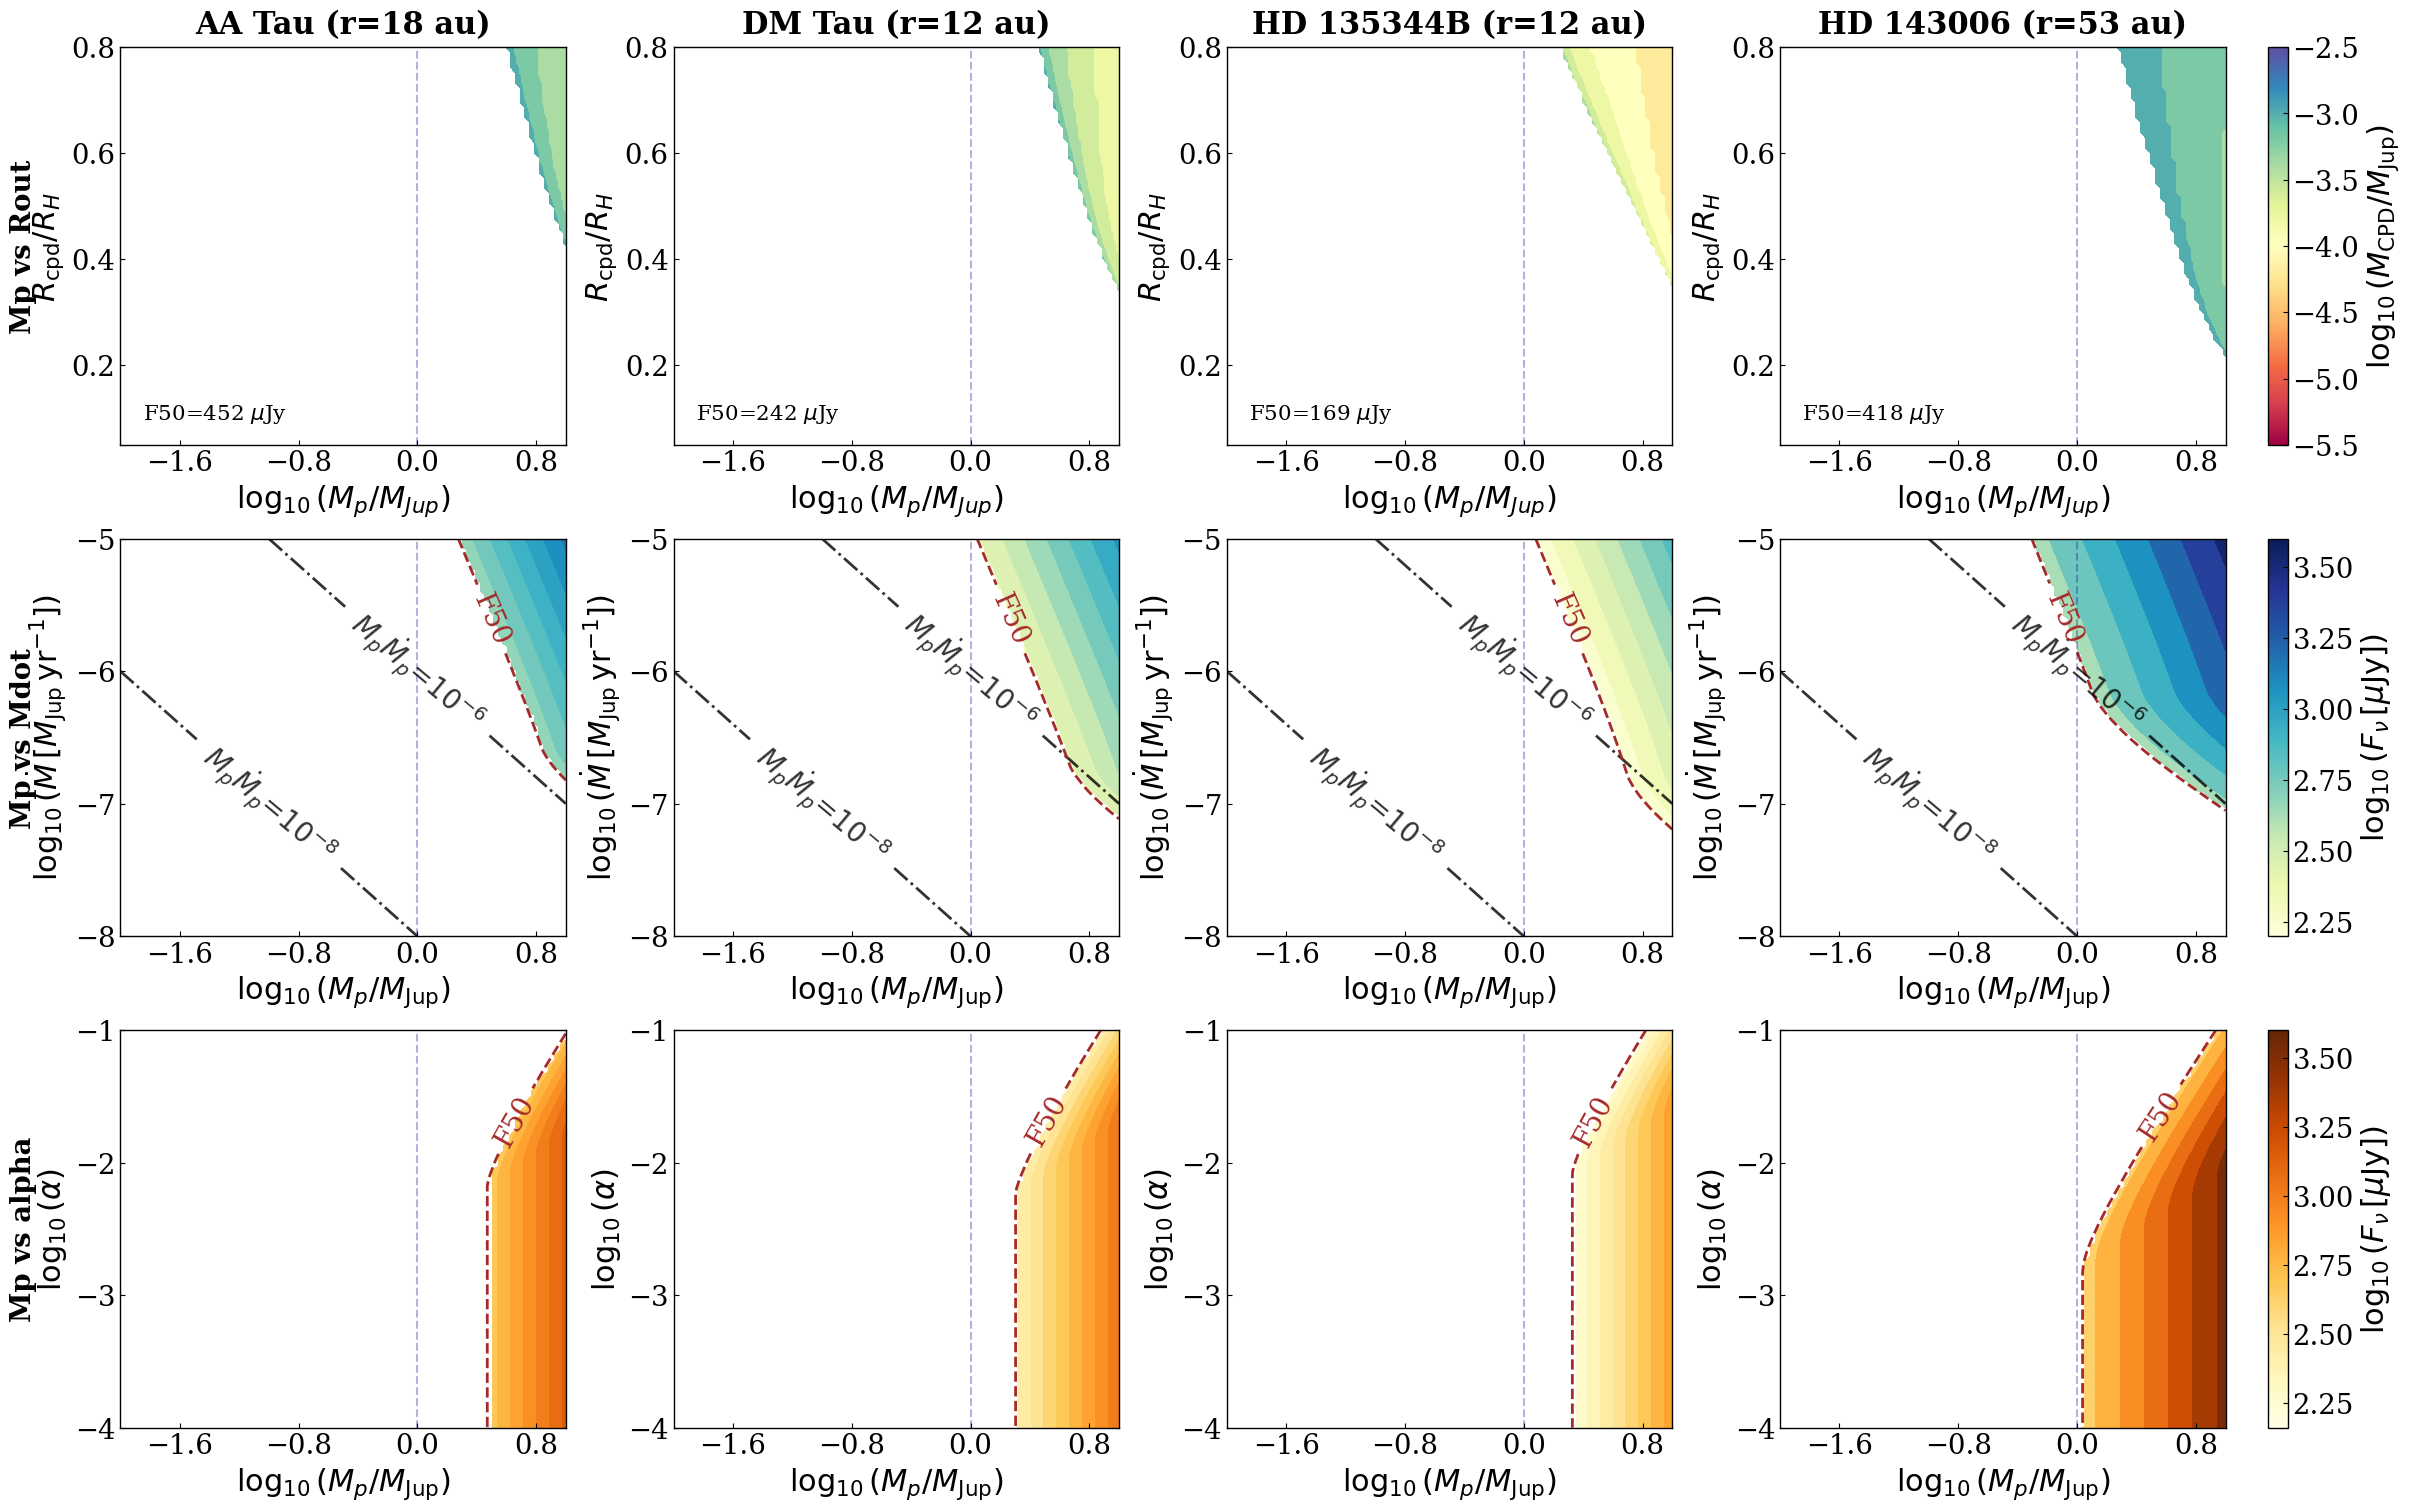

logMp_limit = 5.155695612974758 xlim = (np.float64(-2.0), np.float64(1.0))
logMp_limit = 5.784487379547168 xlim = (np.float64(-2.0), np.float64(1.0))
logMp_limit = 5.387191543484514 xlim = (np.float64(-2.0), np.float64(1.0))


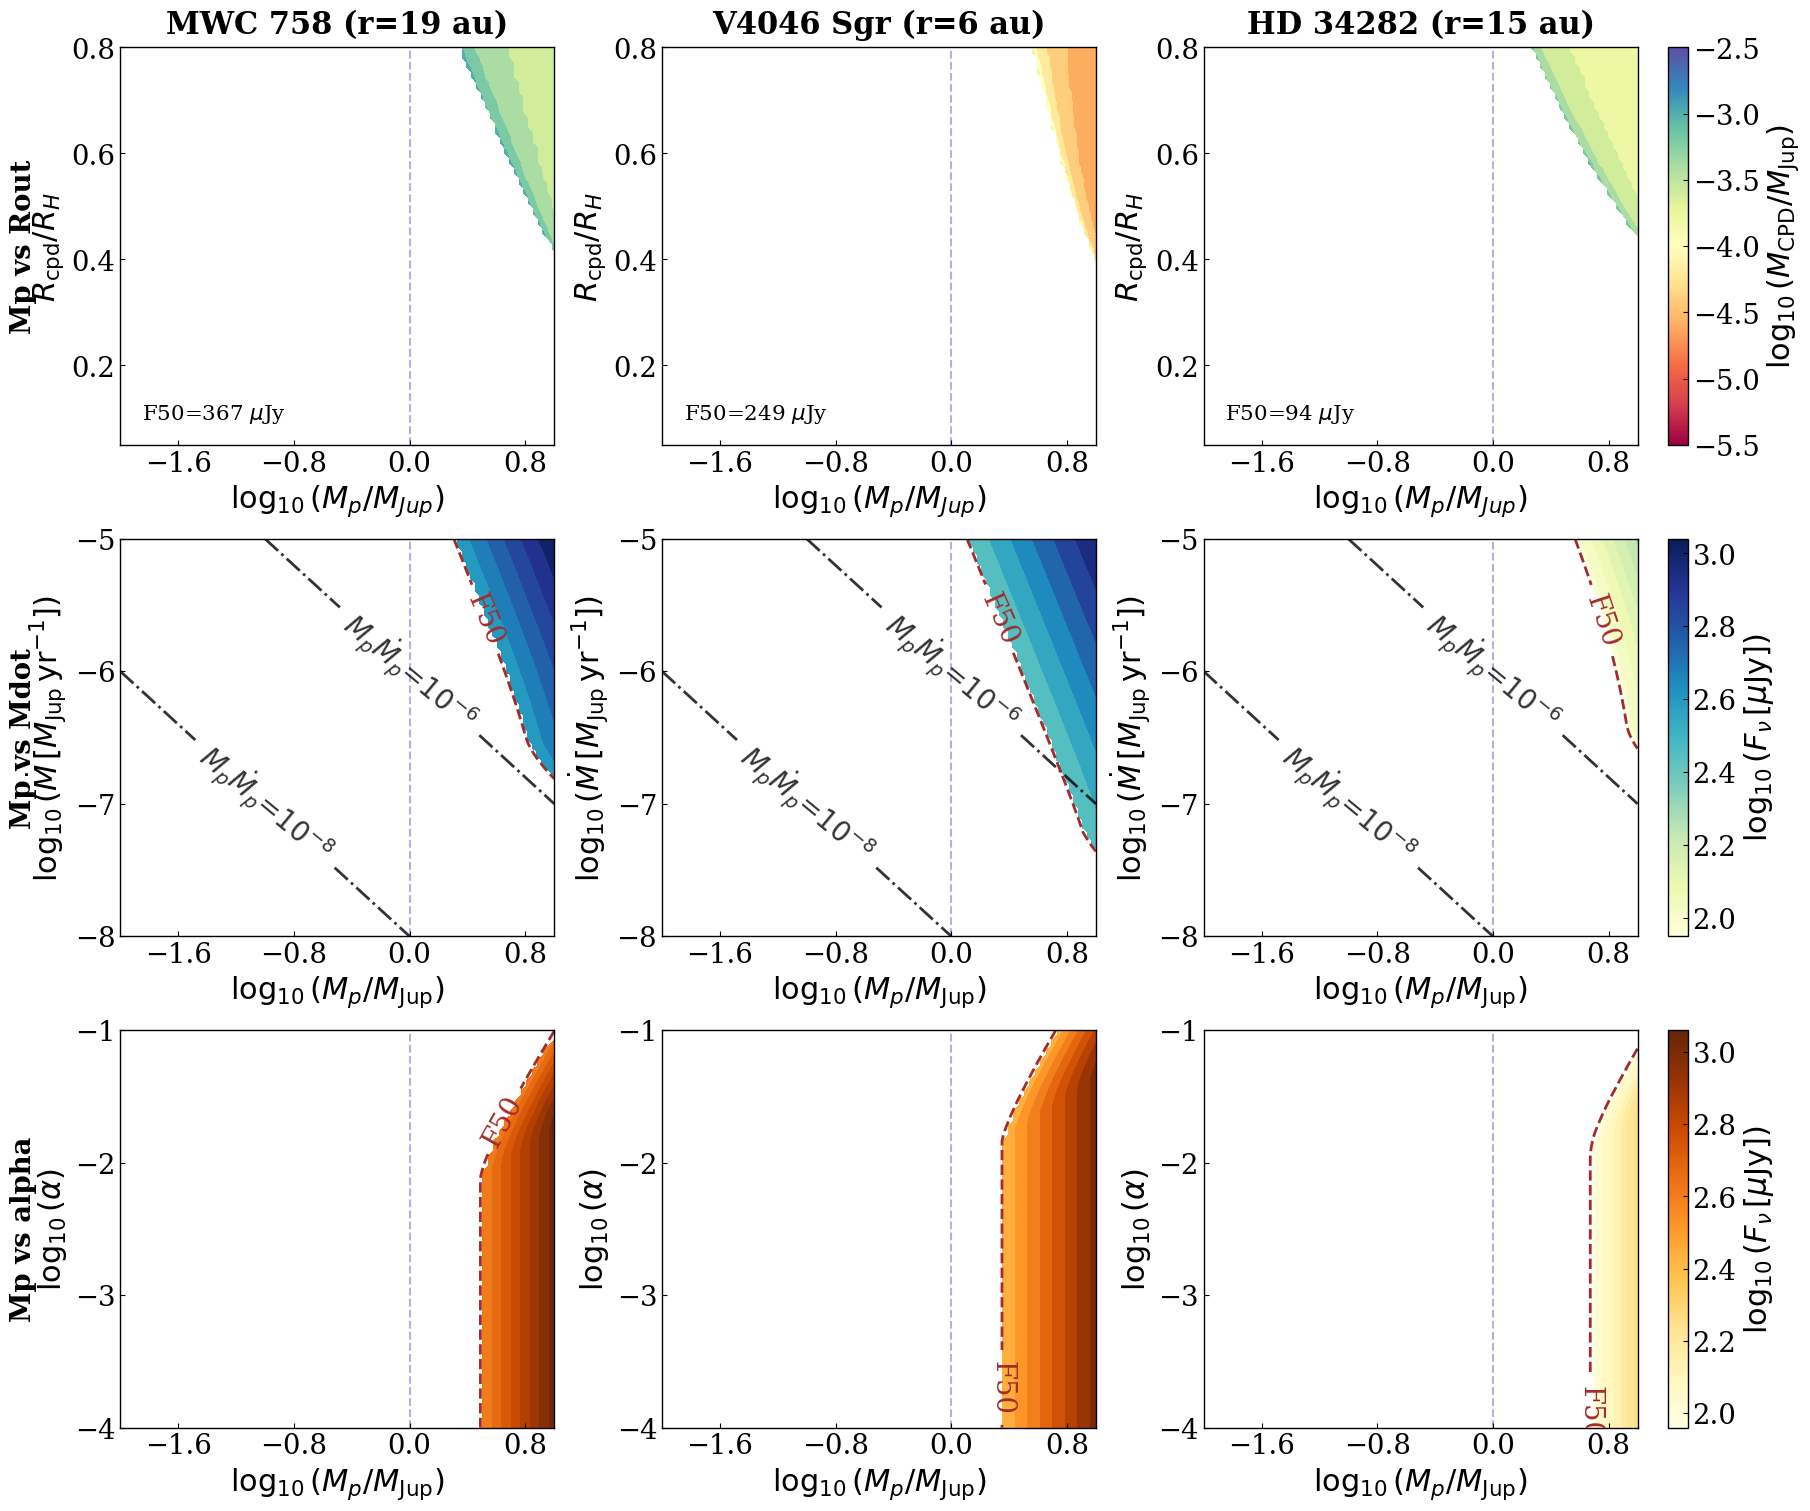

In [127]:
for keys in GROUPS["least"]:
    plot_emission_grid([by_key[k] for k in keys], mode="uvfix", gap_boundary_au=em_boundary)

detectable at mass way above 1 Mjup.  

### 2. Moderately observable

LkCa 15 D9, SY Cha D36, V4046 Sgr D20, J1852 D25

logMp_limit = 5.2882114156000695 xlim = (np.float64(-2.0), np.float64(1.0))
logMp_limit = 3.91190380430342 xlim = (np.float64(-2.0), np.float64(1.0))
logMp_limit = 4.215851143706156 xlim = (np.float64(-2.0), np.float64(1.0))
logMp_limit = 4.602551622394801 xlim = (np.float64(-2.0), np.float64(1.0))


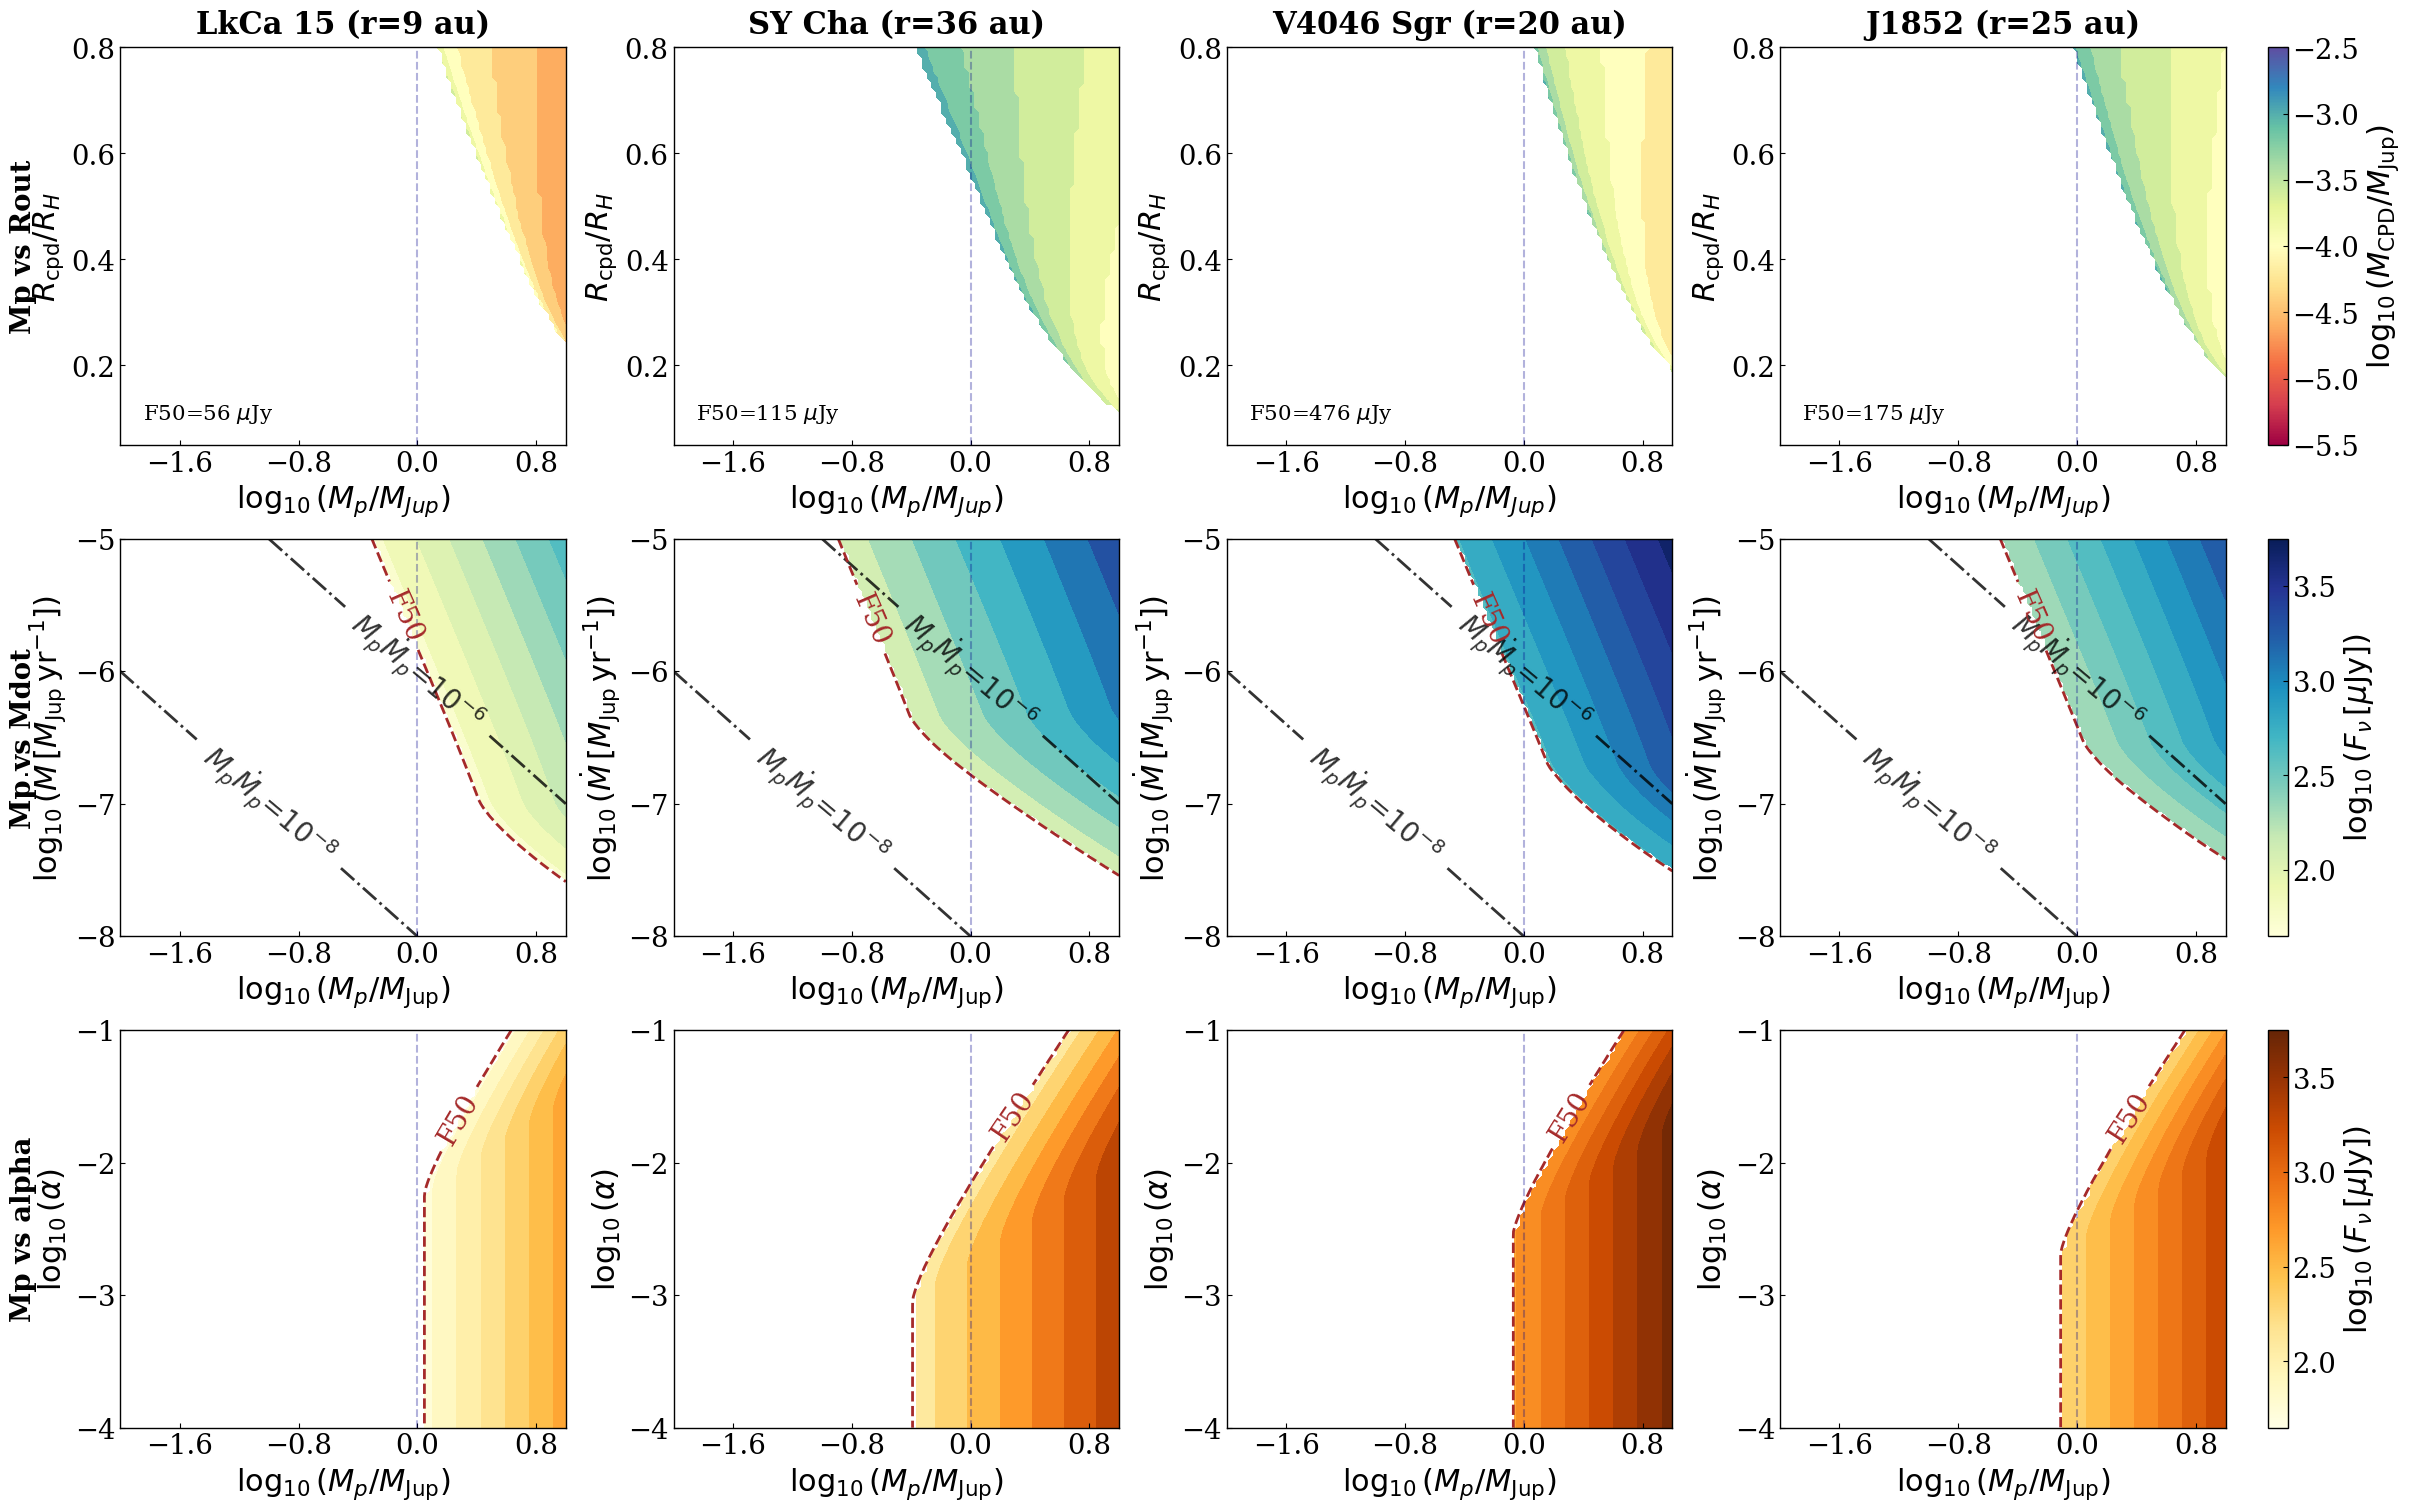

In [128]:
for keys in GROUPS["moderate"]:
    plot_emission_grid([by_key[k] for k in keys], mode="uvfix", gap_boundary_au=em_boundary)

### 3. Most observable

AA Tau D77, DM Tau D69, J1615 D84, LkCa 15 D87, J1604 D52

logMp_limit = 2.1226490711716886 xlim = (np.float64(-2.0), np.float64(1.0))
logMp_limit = 2.155913523494643 xlim = (np.float64(-2.0), np.float64(1.0))
logMp_limit = 3.470615084272021 xlim = (np.float64(-2.0), np.float64(1.0))


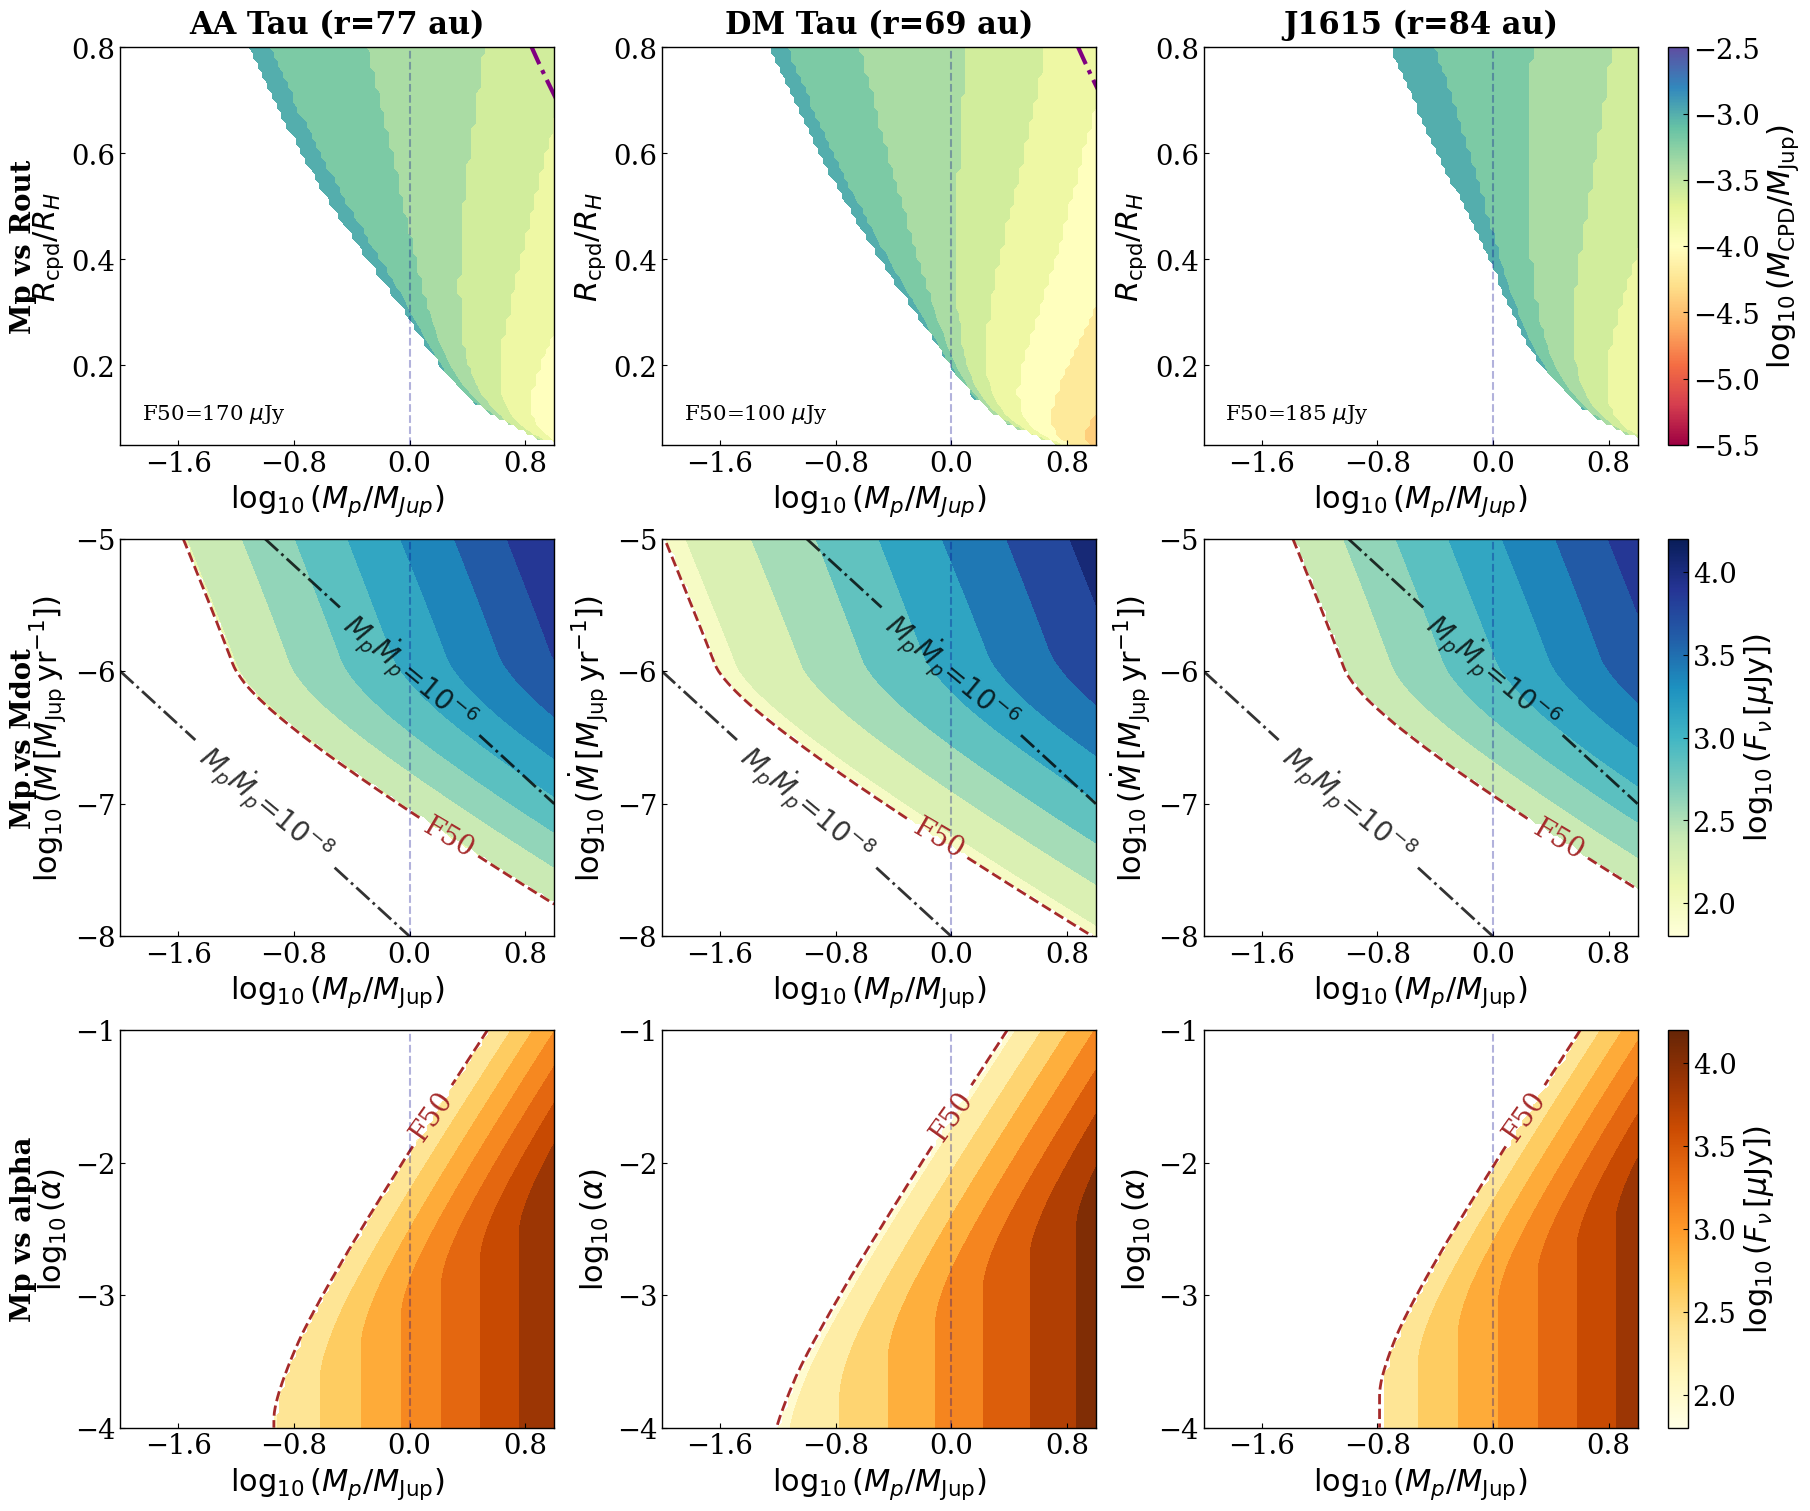

logMp_limit = 2.332381186062188 xlim = (np.float64(-2.0), np.float64(1.0))
logMp_limit = 3.5028795279501734 xlim = (np.float64(-2.0), np.float64(1.0))


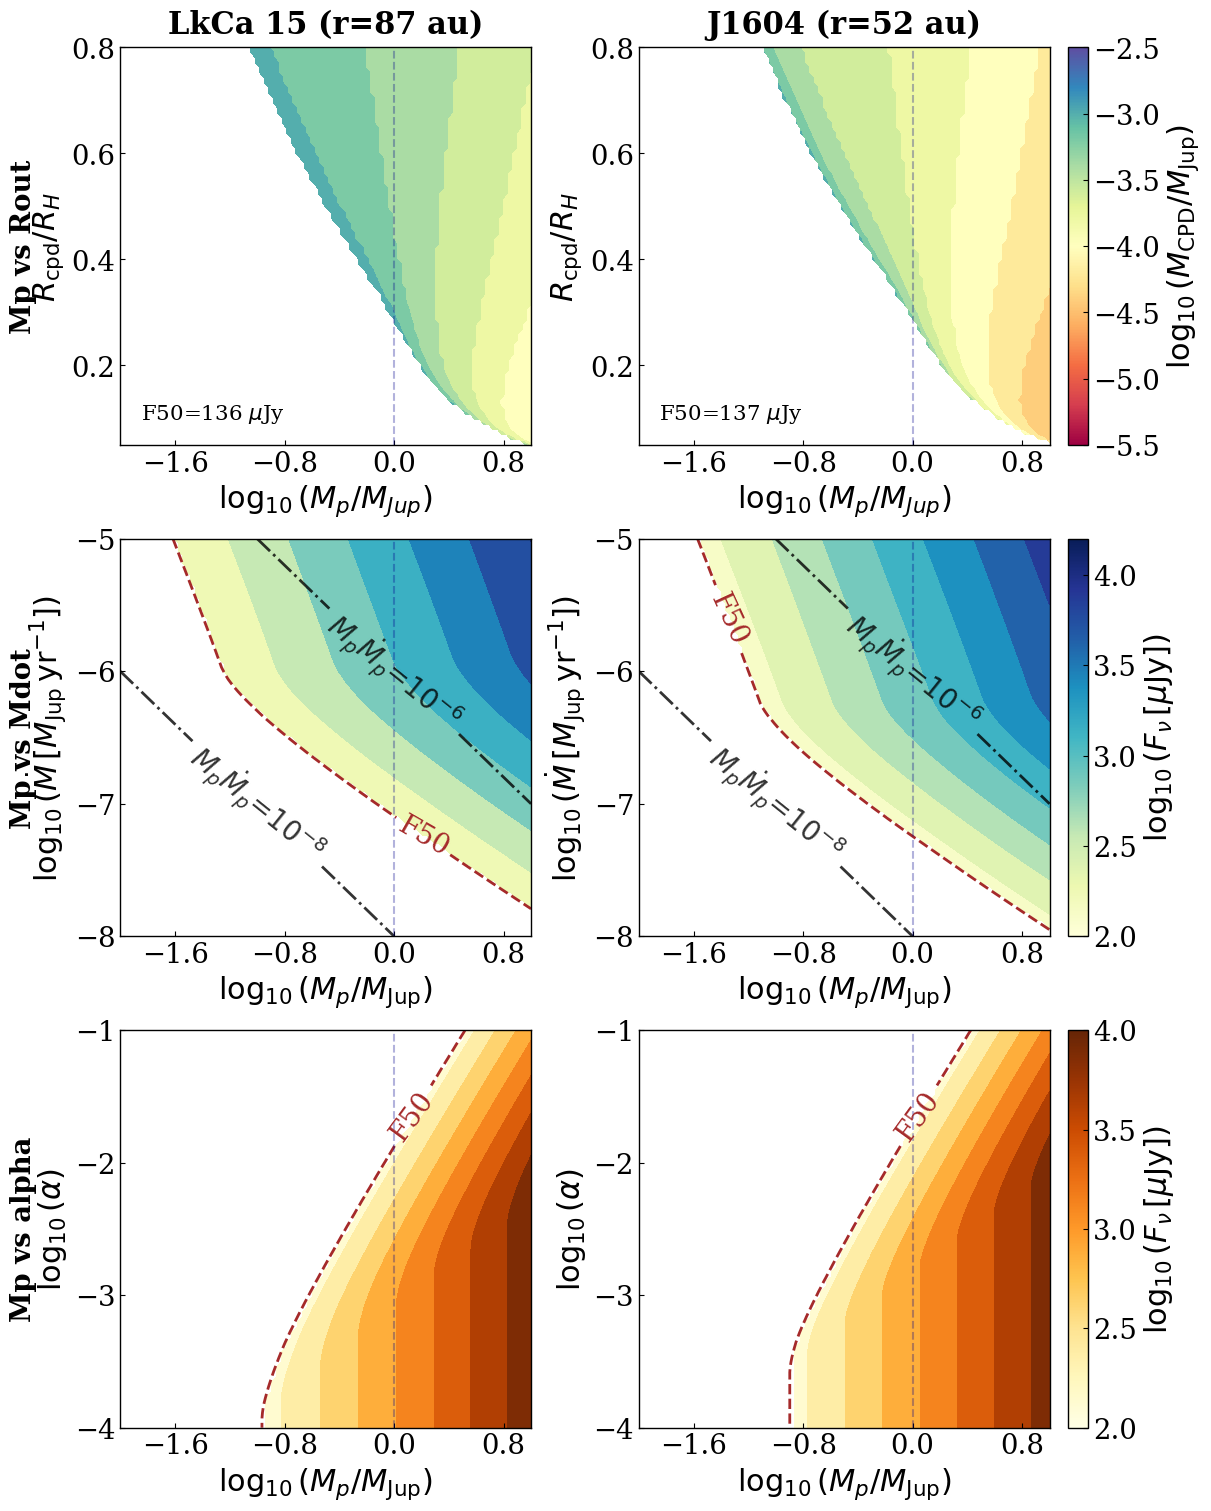

In [129]:
for keys in GROUPS["most"]:
    plot_emission_grid([by_key[k] for k in keys], mode="uvfix", gap_boundary_au=em_boundary)

C1: 340 uJy  (from gap\HD_135344B_C1_uvfix)
DF: 130 uJy  (from gap\HD_135344B_DF_uvfix)
logMp_limit = 4.167242065821009 xlim = (np.float64(-2.0), np.float64(1.0))
logMp_limit = 3.1001447903184105 xlim = (np.float64(-2.0), np.float64(1.0))


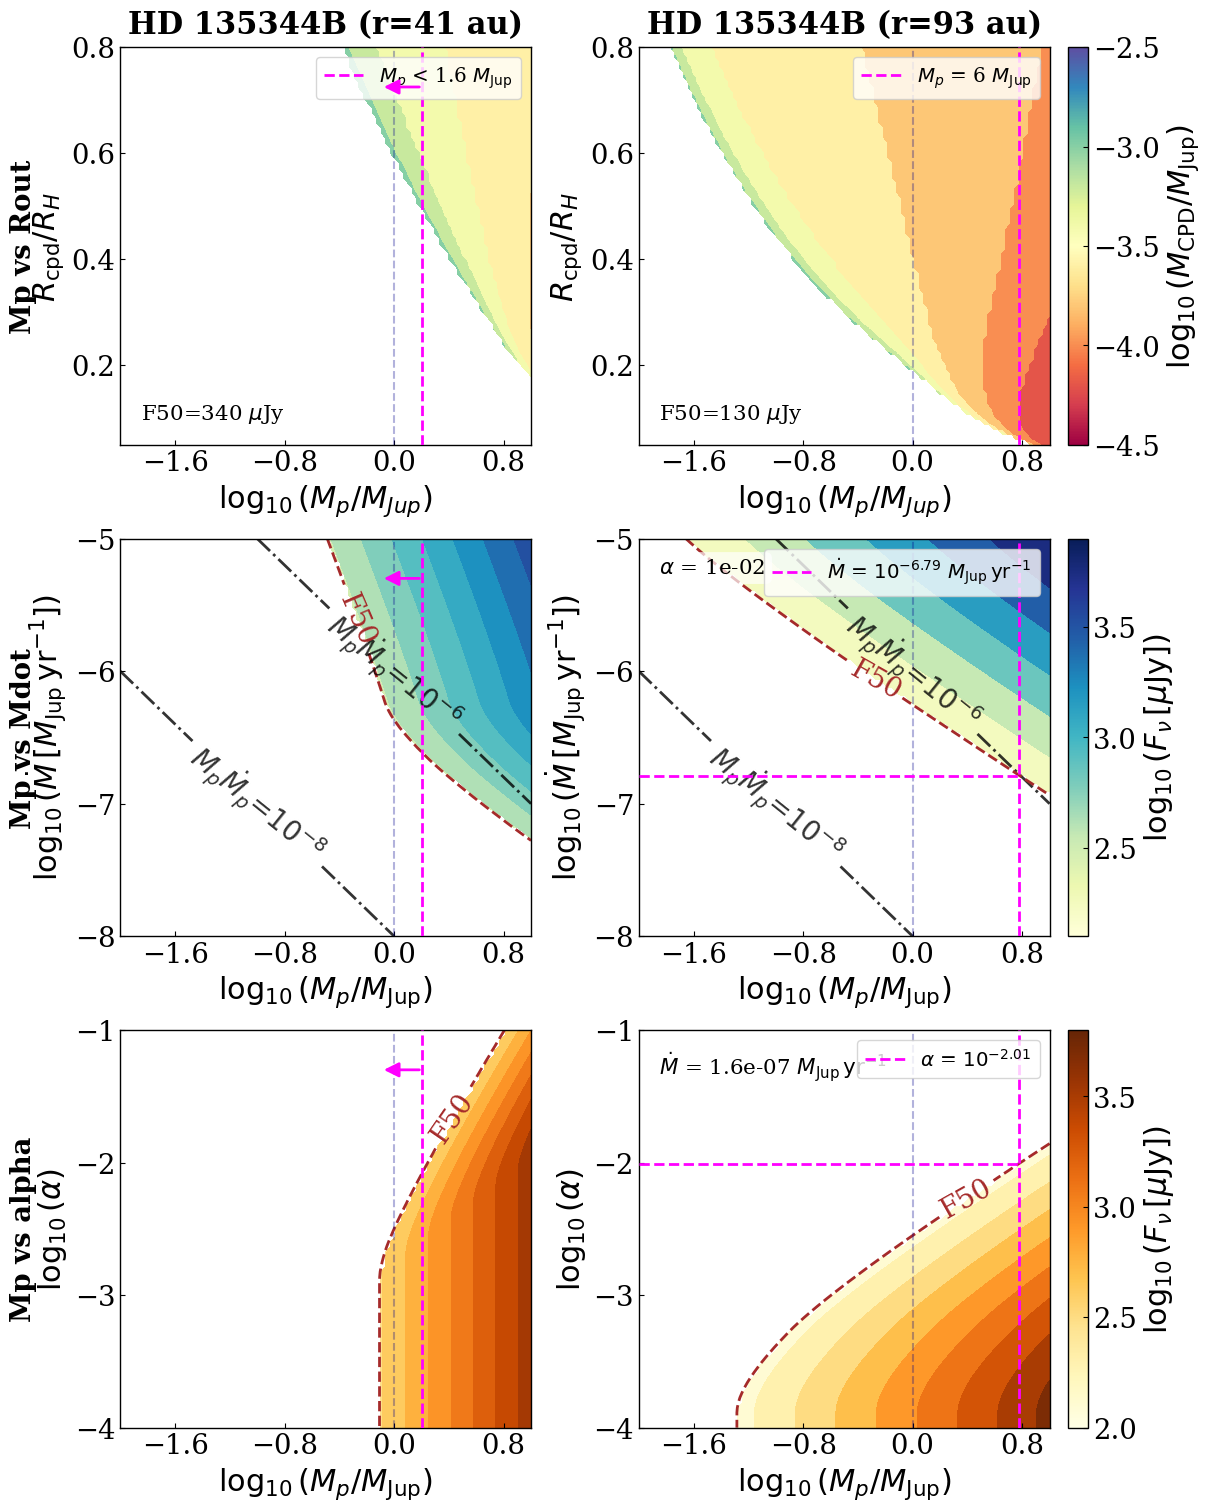

In [130]:
# HD_135344B point candidates -- emission models at the persistent measured flux (not F50), as kink_emission_models.ipynb
# cell 12. That flux is the median recovered flux in the lowest injected bin (the near-constant real peak), taken from the
# uvfix combined recoveries once pulled back, else from the original runs (which gave C1 340, DF 190 uJy). C2 excluded.
cand_flux = {}
for cand, g in [("C1", 2), ("DF", 4)]:
    for folder in (rf"gap\HD_135344B_{cand}_uvfix", rf"gap\HD_135344B_{cand}"):
        f = rf"{base}\{folder}\recoveries\HD_135344B_gap{g}_recoveries.combined.txt"
        if os.path.exists(f):
            a = np.loadtxt(f)
            cand_flux[cand] = round(float(np.median(a[a[:, 0] == a[:, 0].min(), 1])), -1)
            print(f"{cand}: {cand_flux[cand]:.0f} uJy  (from {folder})")
            break

# Format: [disk_name, radius_au, flux_ujy]
candidate_sources = [
    ["HD_135344B", 41, cand_flux["C1"]],   # C1: R=0.30"
    ["HD_135344B", 93, cand_flux["DF"]],   # DF: R=0.69"
]
# the Andrews cache name does not include the flux, so a flux different from the cached 340/190 gets its own tag
mode_cand = "candidate" if (cand_flux["C1"], cand_flux["DF"]) == (340.0, 190.0) else f"candidate_F{cand_flux['C1']:.0f}-{cand_flux['DF']:.0f}"

# gap-boundary hatch: the injection zone's radial half-width (+/-1 beam) instead of a wgap
BEAM_FWHM = 0.0786   # arcsec, robust=-0.5 beam used to size the injection zone
inj_zone_boundary_au = BEAM_FWHM * disk_arr["HD_135344B"][2]
candidate_boundary_au = {(name, r_au): inj_zone_boundary_au for name, r_au, _ in candidate_sources}

# C1: upper limit only (Mp < 1.6 Mjup). DF (Doppler flip): Mp = 6 Mjup, alpha = 1e-2 in its row-2 panel,
# and row 3 at a fixed Mdot = the row-2 (Mp = 6 Mjup) x flux intersection
candidate_mass_upper_limits = {("HD_135344B", 41): 1.6}
candidate_planet_masses = {("HD_135344B", 93): 6}
candidate_zhu2_alpha_by_col = {("HD_135344B", 93): 1e-2}

df_disk, df_radius, df_flux = "HD_135344B", 93, cand_flux["DF"]
Mp_grid2_df, Mdot_grid_df, Flux_vals2_df, _ = get_zhu_mpmdot_grid(
    df_disk, df_radius, mode_cand, alpha=candidate_zhu2_alpha_by_col[(df_disk, df_radius)],
)
j2_df = np.argmin(np.abs(np.log10(Mp_grid2_df) - np.log10(6)))
order2_df = np.argsort(Flux_vals2_df[:, j2_df])
logmdot_F50_df = np.interp(np.log10(df_flux), np.log10(Flux_vals2_df[:, j2_df][order2_df]), np.log10(Mdot_grid_df[order2_df]))
candidate_zhu3_mdot_by_col = {(df_disk, df_radius): 10 ** logmdot_F50_df}

plot_emission_grid(
    candidate_sources, mode=mode_cand, gap_boundary_au=candidate_boundary_au,
    andrews_cmin=-4.5, andrews_cmax=-2.5,
    mass_upper_limits=candidate_mass_upper_limits,
    planet_masses=candidate_planet_masses,
    zhu2_alpha_by_col=candidate_zhu2_alpha_by_col,
    zhu3_mdot_by_col=candidate_zhu3_mdot_by_col,
)

logMp_limit = 4.167242065821009 xlim = (np.float64(-2.0), np.float64(1.0))


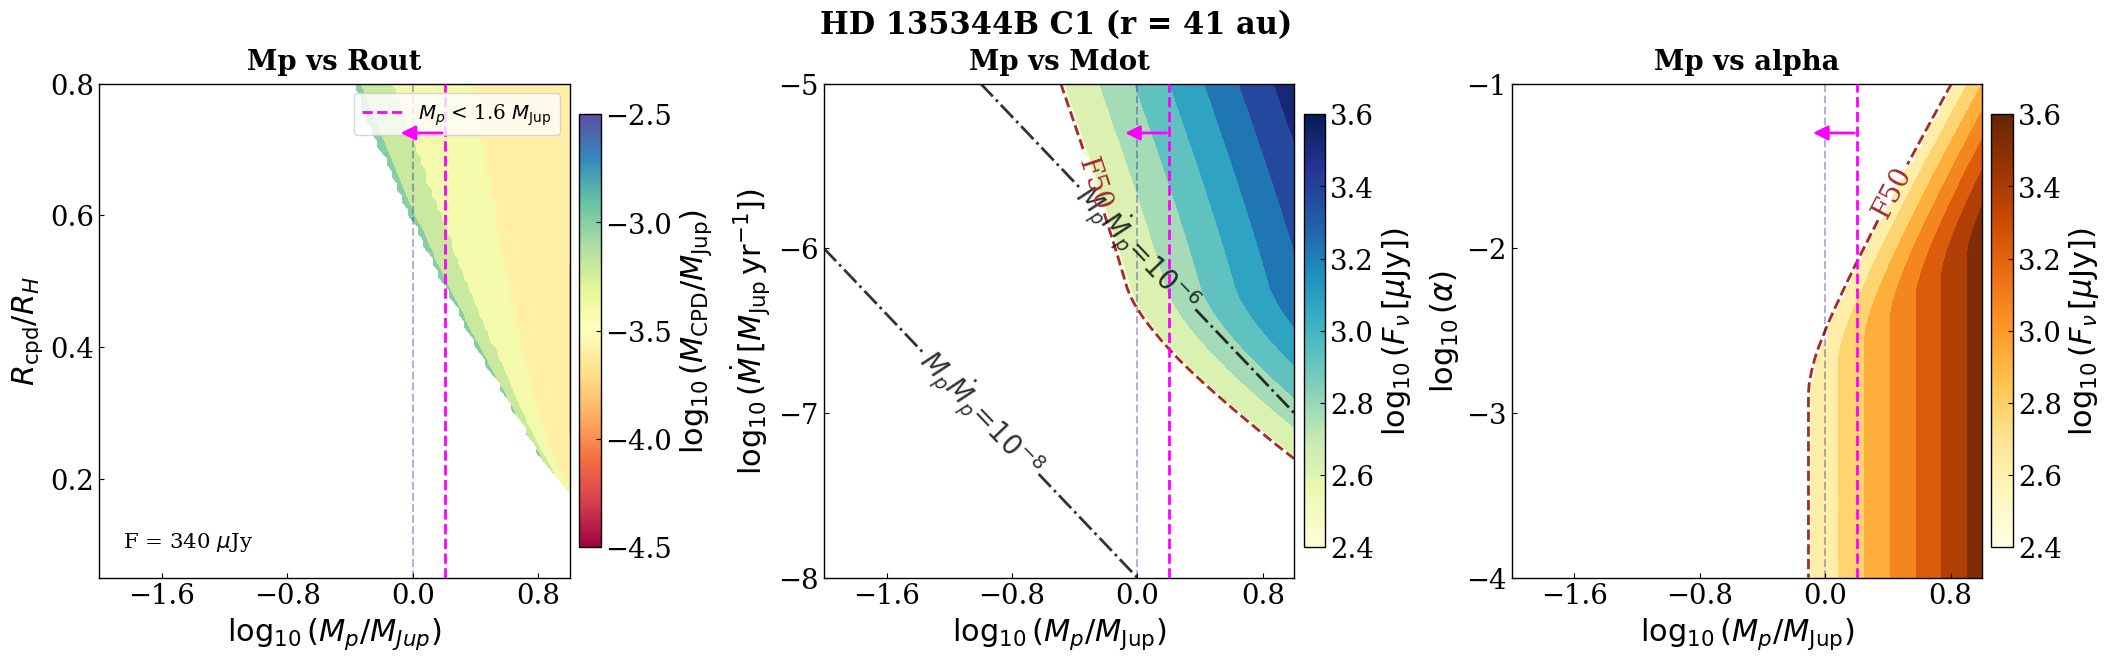

In [131]:
# HD_135344B C1 (r = 41 au) alone, the three emission models side by side: Andrews (Mp vs Rout/R_Hill) | Zhu (Mp vs Mdot)
# | Zhu (Mp vs alpha), each with its own colour bar. Same grids, flux and settings as the C1 column in the cell above
# (run that one first): measured flux, colour range -4.5..-2.5, gap hatching, Mp < 1.6 Mjup upper limit.
disk_name, disk_radius, sigma_ujy = "HD_135344B", 41, cand_flux["C1"]
mass_ul = candidate_mass_upper_limits[(disk_name, disk_radius)]
bmaj = disk_arr[disk_name][4]

fig, axes = plt.subplots(1, 3, figsize=(21, 6.5), constrained_layout=True)

Mp_grid, Rout_frac_grid, Flux_vals, M_cpd_chosen = get_andrews_grid(disk_name, disk_radius, sigma_ujy, mode_cand)
im0 = Andrew_model.plot_flux_map(
    Mp_grid, Rout_frac_grid, Flux_vals, M_cpd_chosen, disk_arr=disk_arr[disk_name], ax=axes[0],
    rp=disk_radius, alpha=1e-3, x_min=-2, x_max=1, y_min=0.05, y_max=0.8, min=-4.5, max=-2.5,
    res_au=disk_arr[disk_name][4] * disk_arr[disk_name][2], sigma_ujy=sigma_ujy, det_sigma=5,
    gap_boundary_au=candidate_boundary_au[(disk_name, disk_radius)],
)
axes[0].text(0.05, 0.05, rf"F = {sigma_ujy:.0f} $\mu$Jy", transform=axes[0].transAxes, ha="left", va="bottom",
             fontsize=rcParams["font.size"] * 0.7)

Mp_grid2, Mdot_grid, Flux_vals2, _ = get_zhu_mpmdot_grid(disk_name, disk_radius, mode_cand, alpha=1e-3)
im1 = Zhu_model.plot_zhu_Mp_Mdot_flux(
    Mp_grid2, Mdot_grid, Flux_vals2, disk_arr=disk_arr[disk_name], rp=disk_radius, alpha=1e-3,
    target_flux_arr=[sigma_ujy], ax=axes[1], beam_major_arcsec=bmaj, plot_thick_thin=False,
)

Mp_grid3, alpha_grid, Flux_map, _ = get_zhu_mpalpha_grid(disk_name, disk_radius, mode_cand)
im2 = Zhu_model.plot_zhu_Mp_alpha_flux(
    Mp_grid3, alpha_grid, Flux_map, disk_arr=disk_arr[disk_name], rp=disk_radius, Mdot=None,
    target_flux_arr=[sigma_ujy], beam_major_arcsec=bmaj, ax=axes[2],
)

for ax, im, cb_label, vmin, vmax, title in [
        (axes[0], im0, r"$\log_{10}(M_{\rm CPD}/M_{\rm Jup})$", -4.5, -2.5, "Mp vs Rout"),
        (axes[1], im1, r"$\log_{10}(F_\nu\,[\mu\rm{Jy}])$", None, None, "Mp vs Mdot"),
        (axes[2], im2, r"$\log_{10}(F_\nu\,[\mu\rm{Jy}])$", None, None, "Mp vs alpha")]:
    ax.set_aspect("auto")
    add_row_colorbar(fig, [ax], [im], label=cb_label, vmin=vmin, vmax=vmax)
    ax.set_title(title, fontsize=rcParams["font.size"] * 0.9, fontweight="bold", pad=10)
    ax.axvline(0, color="darkblue", alpha=0.3, ls="--", lw=1.5, zorder=2)                 # Mp = 1 Mjup reference
    ax.axvline(np.log10(mass_ul), color="magenta", ls="--", lw=2, zorder=5)              # upper limit Mp < 1.6 Mjup
    ax.annotate("", xy=(np.log10(mass_ul) - 0.3, 0.9), xycoords=("data", "axes fraction"),
                xytext=(np.log10(mass_ul), 0.9), textcoords=("data", "axes fraction"),
                arrowprops=dict(arrowstyle="-|>", color="magenta", lw=2), zorder=6)
axes[0].plot([], [], color="magenta", ls="--", lw=2, label=rf"$M_p$ < {mass_ul} $M_{{\rm Jup}}$")
axes[0].legend(fontsize=rcParams["font.size"] * 0.65, loc="upper right")
fig.suptitle(f"HD 135344B C1 (r = {disk_radius} au)", fontsize=rcParams["font.size"], fontweight="bold")
plt.show()

logMp_limit = 2.0728512857133032 xlim = (np.float64(-2.0), np.float64(1.0))
logMp_limit = 2.778796719721006 xlim = (np.float64(-2.0), np.float64(1.0))
logMp_limit = 1.769367860954848 xlim = (np.float64(-2.0), np.float64(1.0))


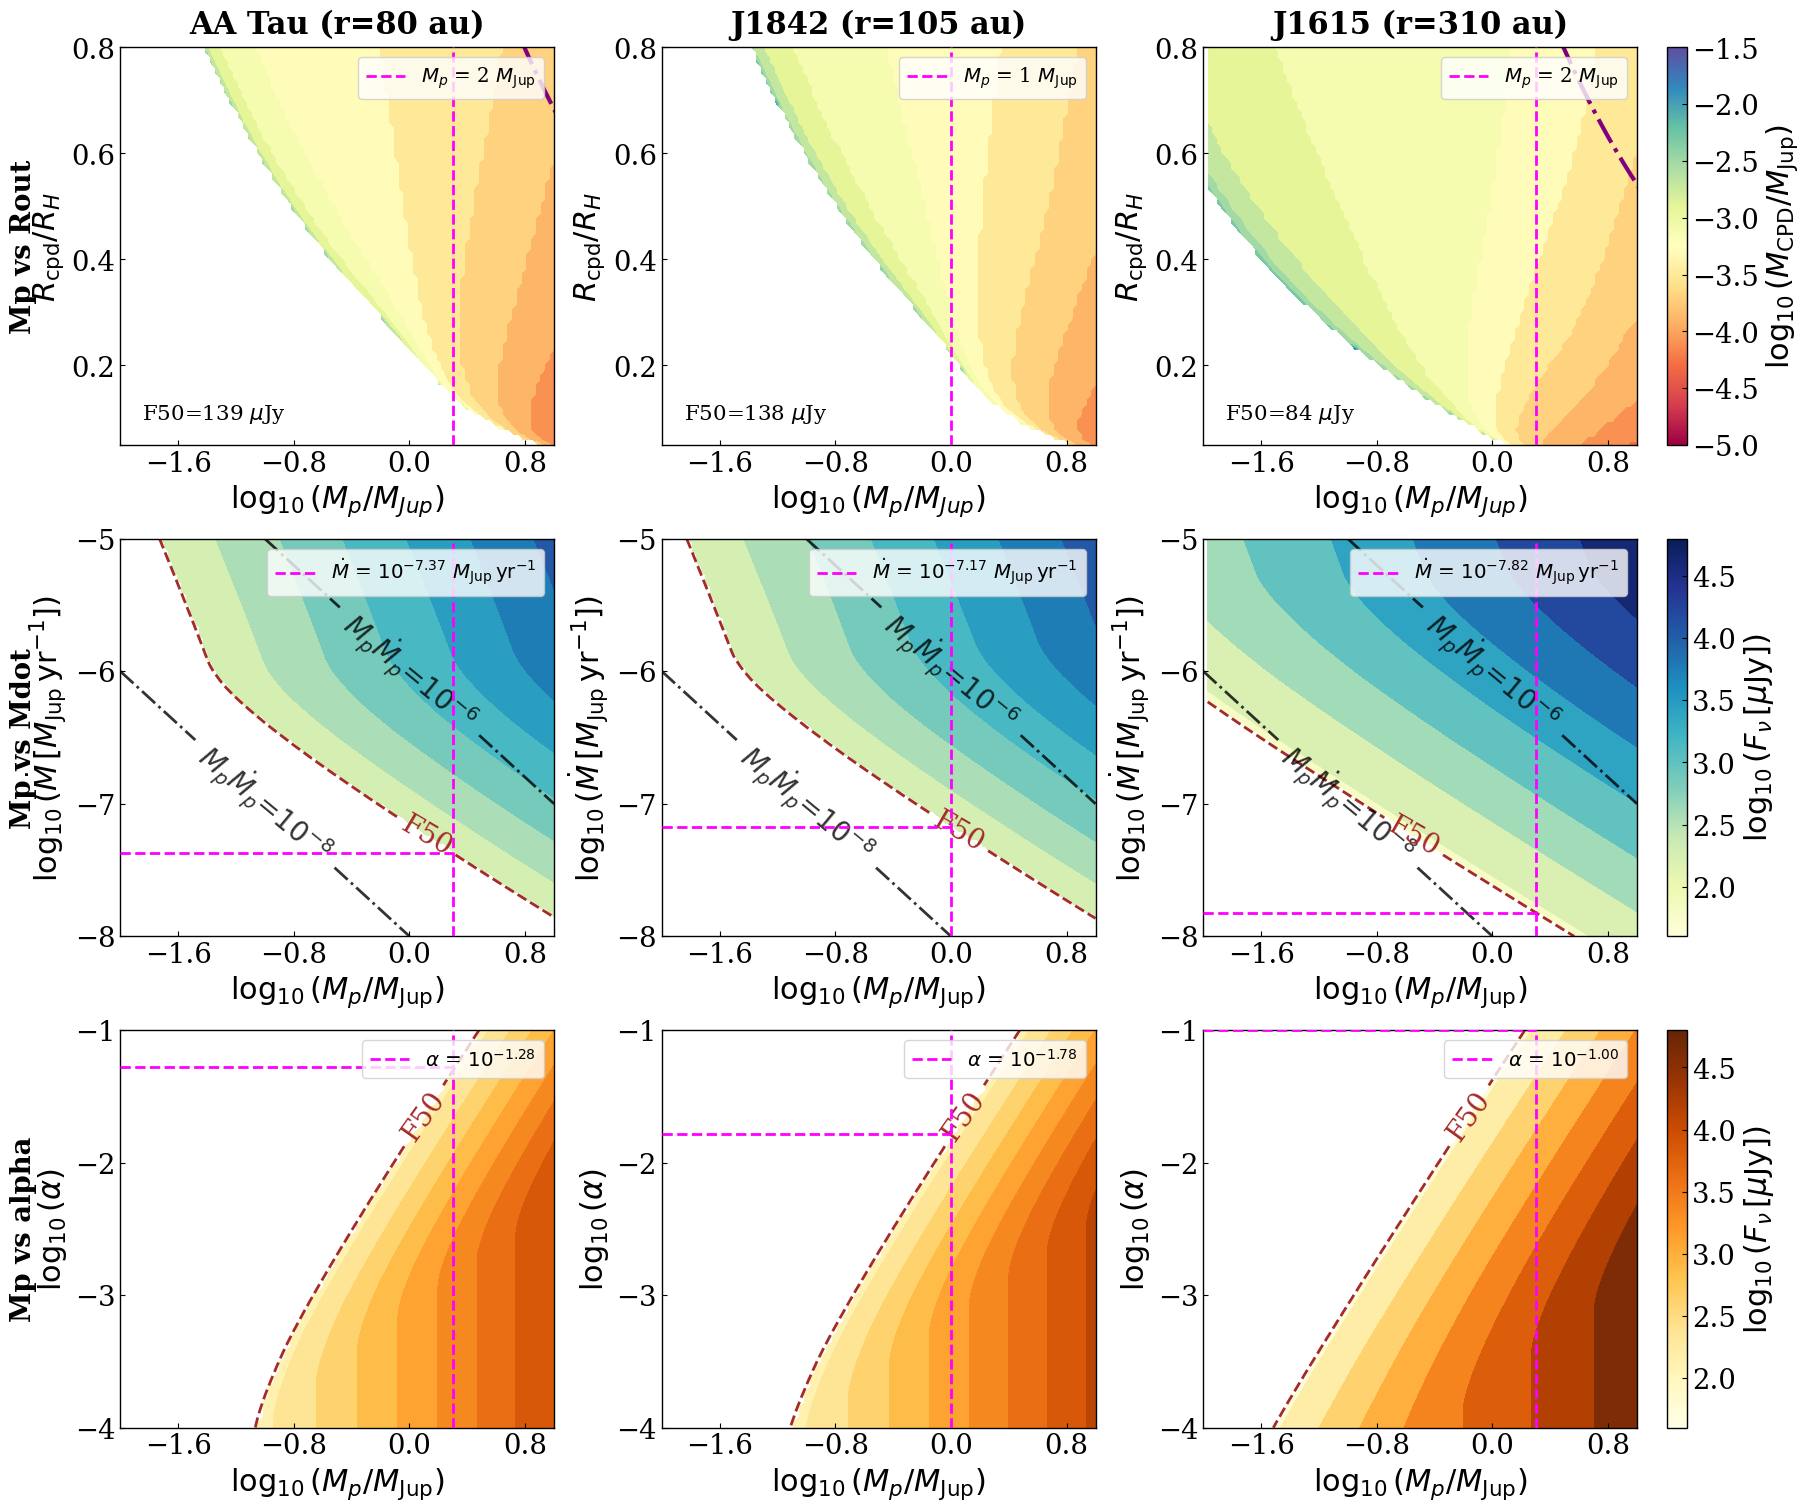

logMp_limit = 1.0103052187832255 xlim = (np.float64(-2.0), np.float64(1.0))
logMp_limit = 2.1424271995705677 xlim = (np.float64(-2.0), np.float64(1.0))


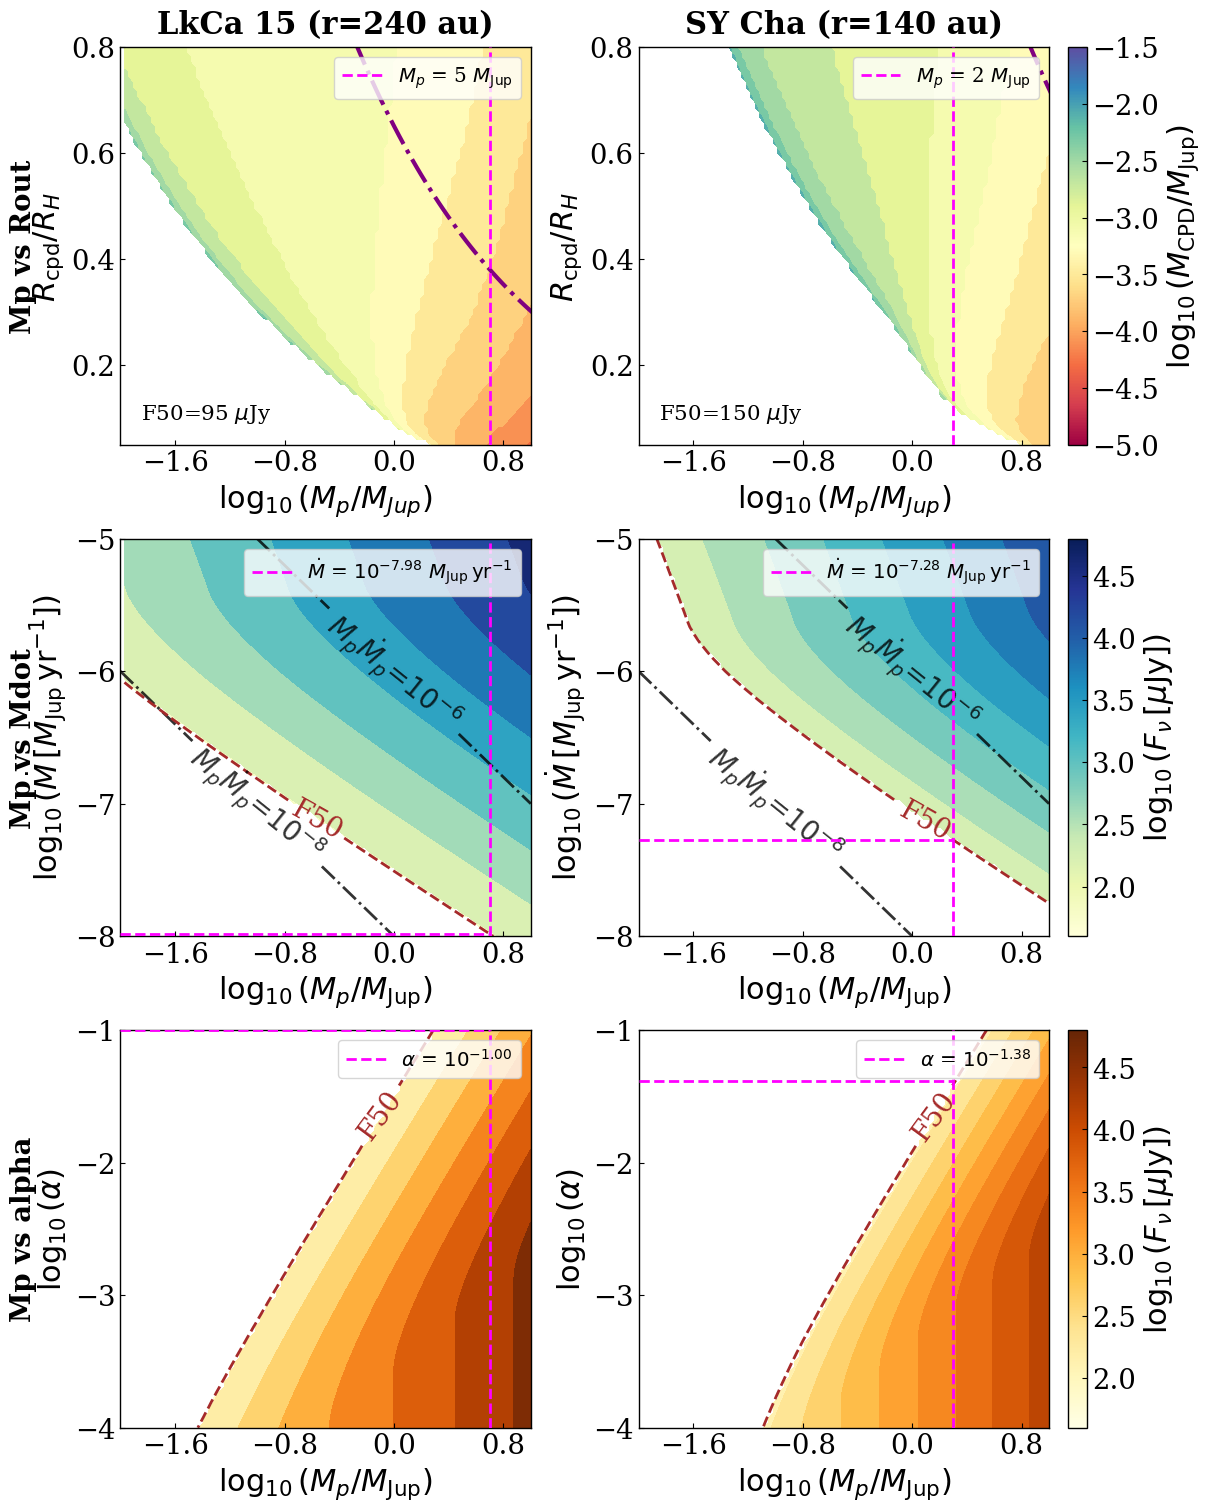

In [132]:
# kink candidates (uv-fixed runs at the Pinte+2025 Table 2 radii) -- copied unchanged from kink_emission_models.ipynb
# cell 19. F50 values from assess_kink0.ipynb; they should match the F50s printed by the kink recovery cell above.
# AA Tau uses the competing-peak flux (139 uJy) since its F50 is only an upper limit (<= 43 uJy).
# Format: [disk_name, radius_au, F50_ujy] -- radius = rkink * distance, F50 = criterion B (assess_kink0.ipynb, 10 uvfix runs)
kink_sources_uvfix = [
    ["AA_Tau",   80, 139.0],   # competing-peak flux (F50 is only an upper limit, <= 43 uJy) -- see markdown above
    ["SY_Cha",  140, 150.4],
    ["J1615",   310,  84.5],
    ["LkCa_15", 240,  94.8],
    ["J1842",   105, 137.5],
]

# planet masses, Pinte+2025 Table 2
kink_planet_mass_table2 = {"AA_Tau": 2, "SY_Cha": 2, "J1615": 2, "LkCa_15": 5, "J1842": 1}

# CPD-mass search extended to 10^-1.5 M_Jup (default 10^-3): SY Cha needs > 10^-3 M_Jup below ~1.3 M_Jup,
# which left a flat white edge in row 1 instead of the physical (Rout > R_planet) boundary
by_name = {s[0]: s for s in kink_sources_uvfix}
plot_emission_grid([by_name["AA_Tau"], by_name["J1842"], by_name["J1615"]], mode="kink_uvfix",
                   planet_masses=kink_planet_mass_table2, andrews_cmax=-1.5, andrews_cmin=-5, andrews_mcpd_max=-1.5, show_mp1_line=False)
plot_emission_grid([by_name["LkCa_15"], by_name["SY_Cha"]], mode="kink_uvfix",
                   planet_masses=kink_planet_mass_table2, andrews_cmax=-1.5, andrews_cmin=-5, andrews_mcpd_max=-1.5, show_mp1_line=False)

ok i will write image caption down here

for kink1 

the image for the kink. the magenta line denotes the model in paper of exoALA XX,  the mass used in the model of that paper,  as shown i  the label of the first row panel . the label in the second and third row, are the that panel;'s x axes value projected by the intersection of the modeeled mass with the f50 flux contour , given the value used for the other degernerate  parameter.  In the first row use Mdot as  Mp/1Myr. And the 2nd row uses alpha as 10^-3,  the 3rd row uses Mdot as Mp/1Myr.  the shown in label flux used are the 50 precent recovery flux, except for aa tau where the top competing peak's flux is used.



plot 1: kink emission model continued. 
